## Image Processing and Computer Vision - Assignment Module #2


Alessandro Teodori (0001247539) alessandro.teodori3@studio.unibo.it

Juan Guillermo Jaramillo Saa (0001217725) juan.jaramillosaa@studio.unibo.it

Ubalducci Michele (0001226810) michele.ubalducci@studio.unibo.it

# Part 1: design your own network

### Contents

**Setup and code** (shared by all parts)
- [Setup](#setup-shared-by-all-parts) — [Paths](#paths), [Reproducibility](#reproducibility)
- [Configuration](#configuration)
- [Data](#data)
- [The network](#the-network)
- [Training](#training)
- [Experiment runner](#experiment-runner)

**Experiments**
1. [From a plain VGG to a residual network: a roadmap](#1-from-a-plain-vgg-to-a-residual-network-a-roadmap)
   — results, [sensitivity to the learning rate](#sensitivity-to-the-learning-rate)
2. [Depth and residual connections](#2-depth-and-residual-connections)
3. [The training recipe](#3-the-training-recipe) —
   [learning rate and weight decay](#step-1--learning-rate-and-weight-decay),
   [random search](#step-2--random-search),
   [confirmation with seeds](#step-3--confirmation-with-seeds)
4. [Longer training and the final model](#4-longer-training-and-the-final-model)
5. [Ablation of the final model](#5-ablation-of-the-final-model)

[Conclusions](#conclusions)

We train a convolutional network from scratch on the 100 aircraft variants of FGVC-Aircraft, using only PyTorch
primitives (`nn.Conv2d`, `nn.BatchNorm2d`, `nn.Linear`, ...). Our goal is a network in which every component is
justified by a measurement, so we build it step by step and let each result motivate the next experiment:

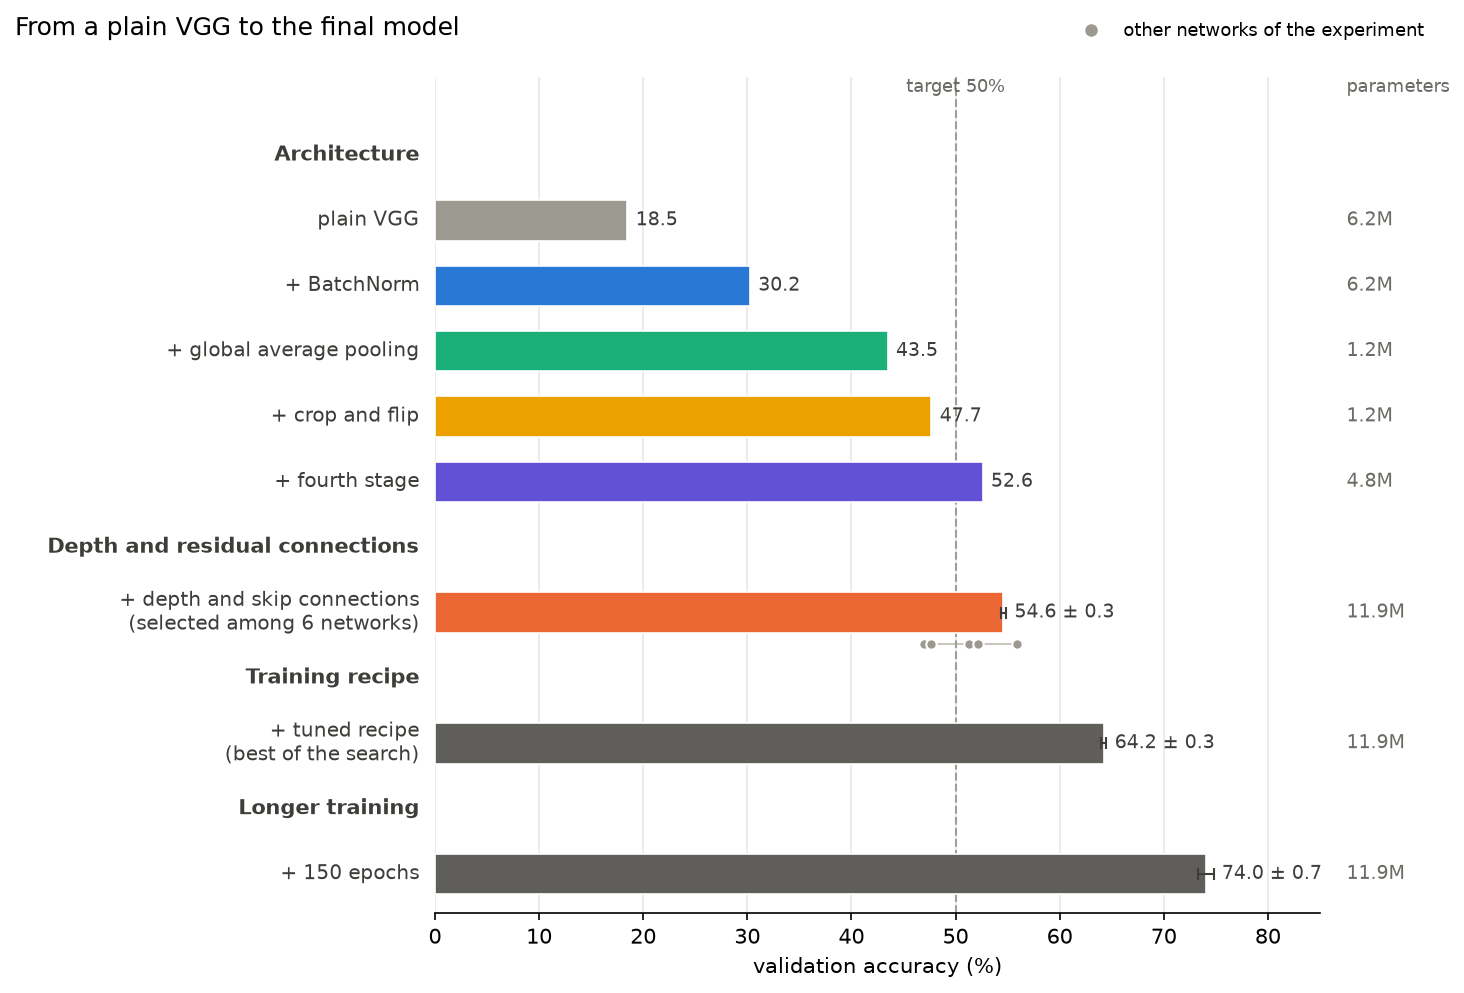

1. **Roadmap.** We start from a plain VGG-style network and add one design choice at a time (BatchNorm, global
   average pooling, augmentation, a fourth stage), so that every difference in accuracy has a single cause.
2. **Depth and residual connections.** On top of the last network of the roadmap (which happened to be the best), we compare plain and residual networks of increasing depth.
3. **Training recipe.** The three best networks receive the same hyperparameter search over the regularizers and the learning-rate schedule.
4. **Longer training.** The tuned networks are trained for 150 epochs instead of 70, and the final model is selected.
5. **Ablation.** Every component of the final model is removed in turn, to measure what it contributes.

All runs use 224×224 images, batch 64 and SGD with momentum 0.9. The roadmap and the depth experiment train every network for 70 epochs at three learning rates and keep the best, since different networks prefer different learning rates. The training recipe then tunes the learning rate together with the other hyperparameters, and the final model and its ablation are trained for 150 epochs. All choices are made on the validation split while the test accuracy is reported but never used to select anything.

**Result.** The final model is a residual network with 31 convolutional layers, trained for 150 epochs with the tuned recipe: **74.0% ± 0.7 validation and 74.2% ± 0.2 test accuracy** (mean ± standard deviation over three seeds).

## Setup (shared by all parts)

**How to run.** The notebook runs top to bottom, locally or on Colab. All the runs reported below are stored in a
shared Google Drive folder (a copy of the `results` directory), downloaded automatically with `gdown` as a single
archive. With `TRAIN = False` (the default) the notebook only loads the stored results and shows its tables and plots:
no dataset and no training are needed. With `TRAIN = True` the training cells (final model, ablation, Part 2A)
download the dataset and train the runs whose result does not exist yet; `RETRAIN = True` trains them again even if
it exists. The images are read and preprocessed on the fly, on the CPU. Locally, results are kept in the `results`
directory of the repository and the dataset in its `data` directory (git-ignored, created if missing); on Colab both
stay on the temporary disk of the session.

**Note.** The stored results were produced with an equivalent pipeline that kept the dataset on the GPU and
computed the augmentation on the GPU with mixed precision. The training code of this notebook is the same algorithm
with standard torchvision transforms in float32, so retraining gives similar, not identical, numbers.

In [241]:
%pip install -q gdown

Note: you may need to restart the kernel to use updated packages.


In [242]:
import json
import math
import random
import re
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets
from torchvision.models import resnet18, ResNet18_Weights
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms as T
from torchvision.transforms import functional as TF
import matplotlib.pyplot as plt
from IPython.display import display
from typing import cast
from tqdm.auto import tqdm

IN_COLAB = "google.colab" in sys.modules
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")

TRAIN = False  # True: run the training cells (final model, ablation, Part 2A)
RETRAIN = False  # True: with TRAIN, retrain the runs whose JSON already exists too
print(f"device: {DEVICE}" + (f" ({torch.cuda.get_device_name()})" if DEVICE.type == "cuda" else "")
      + f" | torch {torch.__version__}")

device: mps | torch 2.14.1


### Paths

Experimental results and the dataset are kept locally (`results/`, `data/`) when the notebook runs locally, and on the
temporary disk of the session on Colab. The stored results of the project are then downloaded with `gdown` as a single archive (about 2 MB)

In [243]:
if IN_COLAB:
    RESULTS_ROOT = Path("/content/results")
    DATA_ROOT = Path("/content/data")
else:
    REPO_DIR = Path.cwd().parent if Path.cwd().name == "code" else Path.cwd()
    RESULTS_ROOT = REPO_DIR / "results"
    DATA_ROOT = REPO_DIR / "data"  # dataset: git-ignored, created if missing
RESULTS_DIR = RESULTS_ROOT / "part1"
RESULTS_DIR_2A = RESULTS_ROOT / "part2A"
RESULTS_DIR_2B = RESULTS_ROOT / "part2B"

for d in (RESULTS_DIR, RESULTS_DIR_2A, RESULTS_DIR_2B, DATA_ROOT):
    d.mkdir(parents=True, exist_ok=True)
print("results ->", RESULTS_ROOT)

RESULTS_ARCHIVE_ID = "1TWAHMvXZ09Bg9gUZplJ3s_uWjsGc_-hk"  # Google Drive file id
FETCH_RESULTS = True  # False: use only the results already in RESULTS_ROOT


def fetch_results(file_id, dest_root):
    import gdown, tarfile, tempfile

    with tempfile.TemporaryDirectory() as tmp:
        archive = f"{tmp}/results.tar.gz"
        if gdown.download(id=file_id, output=archive, quiet=True, use_cookies=False) is None:
            raise RuntimeError("download failed")
        with tarfile.open(archive) as tar:
            tar.extractall(dest_root, filter="data")
            n = sum(m.isfile() for m in tar.getmembers())
    print(f"results from Google Drive: {n} files extracted into {dest_root}")


if FETCH_RESULTS:
    try:
        fetch_results(RESULTS_ARCHIVE_ID, RESULTS_ROOT)
    except Exception as e:
        print(
            f"WARNING: could not download the results from Google Drive ({e}); using the ones already in {RESULTS_ROOT}"
        )

results -> /Users/juan/Desktop/100planes-X-IPCV/results
results from Google Drive: 243 files extracted into /Users/juan/Desktop/100planes-X-IPCV/results


### Reproducibility

We seed every source of randomness (initialization, data order, augmentation) and keep cuDNN deterministic, so that a
configuration trained twice with the same seed gives the same result. Training a configuration with different seeds
is how we measure run-to-run noise.

In [244]:
def fix_random(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


fix_random(42)

## Configuration

A base configuration holds every choice shared by all runs; each experiment changes only what it studies.

- **Optimizer: SGD with momentum 0.9** — the optimizer of VGG and ResNet
- **Learning-rate sweep.** Each configuration is trained at learning rates 0.1, 0.05 and 0.01 and represented by its best one. The best learning rate depends on the network so a single value for every step could make a step look harmful only because the value does not
  suit it.
- **Schedule: linear warmup for 3 epochs, then cosine decay to zero**
- **Budget: 70 epochs, batch 64** 
- **Resolution: 224x224**, the standard resolution of ImageNet training.
- **Regularizers off** (weight decay, label smoothing, dropout, random erasing) until the training recipe, so that the
  roadmap and the depth experiment measure the architecture alone.

In [245]:
BASE = dict(
    seed=42,
    # data
    img_size=224,
    augment=False,
    crop_scale=(0.5, 1.0),  # RandomResizedCrop: area of the crop, as a fraction of the image
    # architecture
    stem=(32, 32, 64),
    channels=(64, 128, 256),
    blocks=(1, 1, 1),  # blocks per stage; a block is two 3x3 convs
    batchnorm=False,
    gap=False,
    residual=False,
    dropout=0.0,  # before the classifier; searched in the training recipe
    # training
    epochs=70,
    batch_size=64,
    lr=0.05,  # overridden by the sweep
    momentum=0.9,
    weight_decay=0.0,  # searched in the training recipe
    label_smoothing=0.0,  # searched in the training recipe
    random_erasing=0.0,  # probability of erasing a random rectangle; searched in the training recipe
    warmup_epochs=3,
)

# every configuration is trained at each of these learning rates and represented by its best one (on validation)
LR_SWEEP = [0.1, 0.05, 0.01]

# extra seeds for the depth x residual networks and for the recipe (seed 42 comes from the sweep)
SEEDS = [42, 43, 44]

# The ladder: each step adds exactly one change on top of all the previous ones
STEPS = [
    ("s0_vgg", dict()),
    ("s1_bn", dict(batchnorm=True)),
    ("s2_gap", dict(gap=True)),
    ("s3_aug", dict(augment=True)),
    ("s4_stage4", dict(channels=(64, 128, 256, 512), blocks=(1, 1, 1, 1))),
]


def cumulative(steps):
    # [(name, overrides of that step and of all the steps before it)]
    acc, out = {}, []
    for name, change in steps:
        acc = {**acc, **change}
        out.append((name, dict(acc)))
    return out


LADDER = cumulative(STEPS)
S4 = LADDER[-1][1]

# Depth x residual, on top of s4: three depths, each with and without skip connections (see the section for why)
GRID = [
    ("plain_1111", dict(S4, blocks=(1, 1, 1, 1), residual=False)),  # = s4
    ("res_1111", dict(S4, blocks=(1, 1, 1, 1), residual=True)),
    ("plain_2222", dict(S4, blocks=(2, 2, 2, 2), residual=False)),  # ResNet-18 layout
    ("res_2222", dict(S4, blocks=(2, 2, 2, 2), residual=True)),
    ("plain_3461", dict(S4, blocks=(3, 4, 6, 1), residual=False)),  # ResNet-34 layout, one 512-block
    ("res_3461", dict(S4, blocks=(3, 4, 6, 1), residual=True)),
]

# Recipe tuning (see its section): the TUNE_N best networks of the grid get the same search
TUNE_N = 3
TUNE_LRS = [0.1, 0.05]  # grid search: learning rate x weight decay (log-spaced)
TUNE_WDS = [1e-4, 5e-4, 1e-3, 2e-3, 5e-3, 1e-2]
TOP_K = 2  # best configurations of each network confirmed with the other seeds

# Longer training: the tuned networks, each with its best configuration, trained for more epochs
LONG_EPOCHS = 150

## Data

FGVC-Aircraft (`torchvision.datasets.FGVCAircraft`, `annotation_level="variant"`) has 100 classes and 3,334 / 3,333 / 3,333 images in the training / validation / test splits: about **33 training images per class**. With so few images a network can memorize the training set long before it learns features that generalize, and this is the problem most of the following steps address.

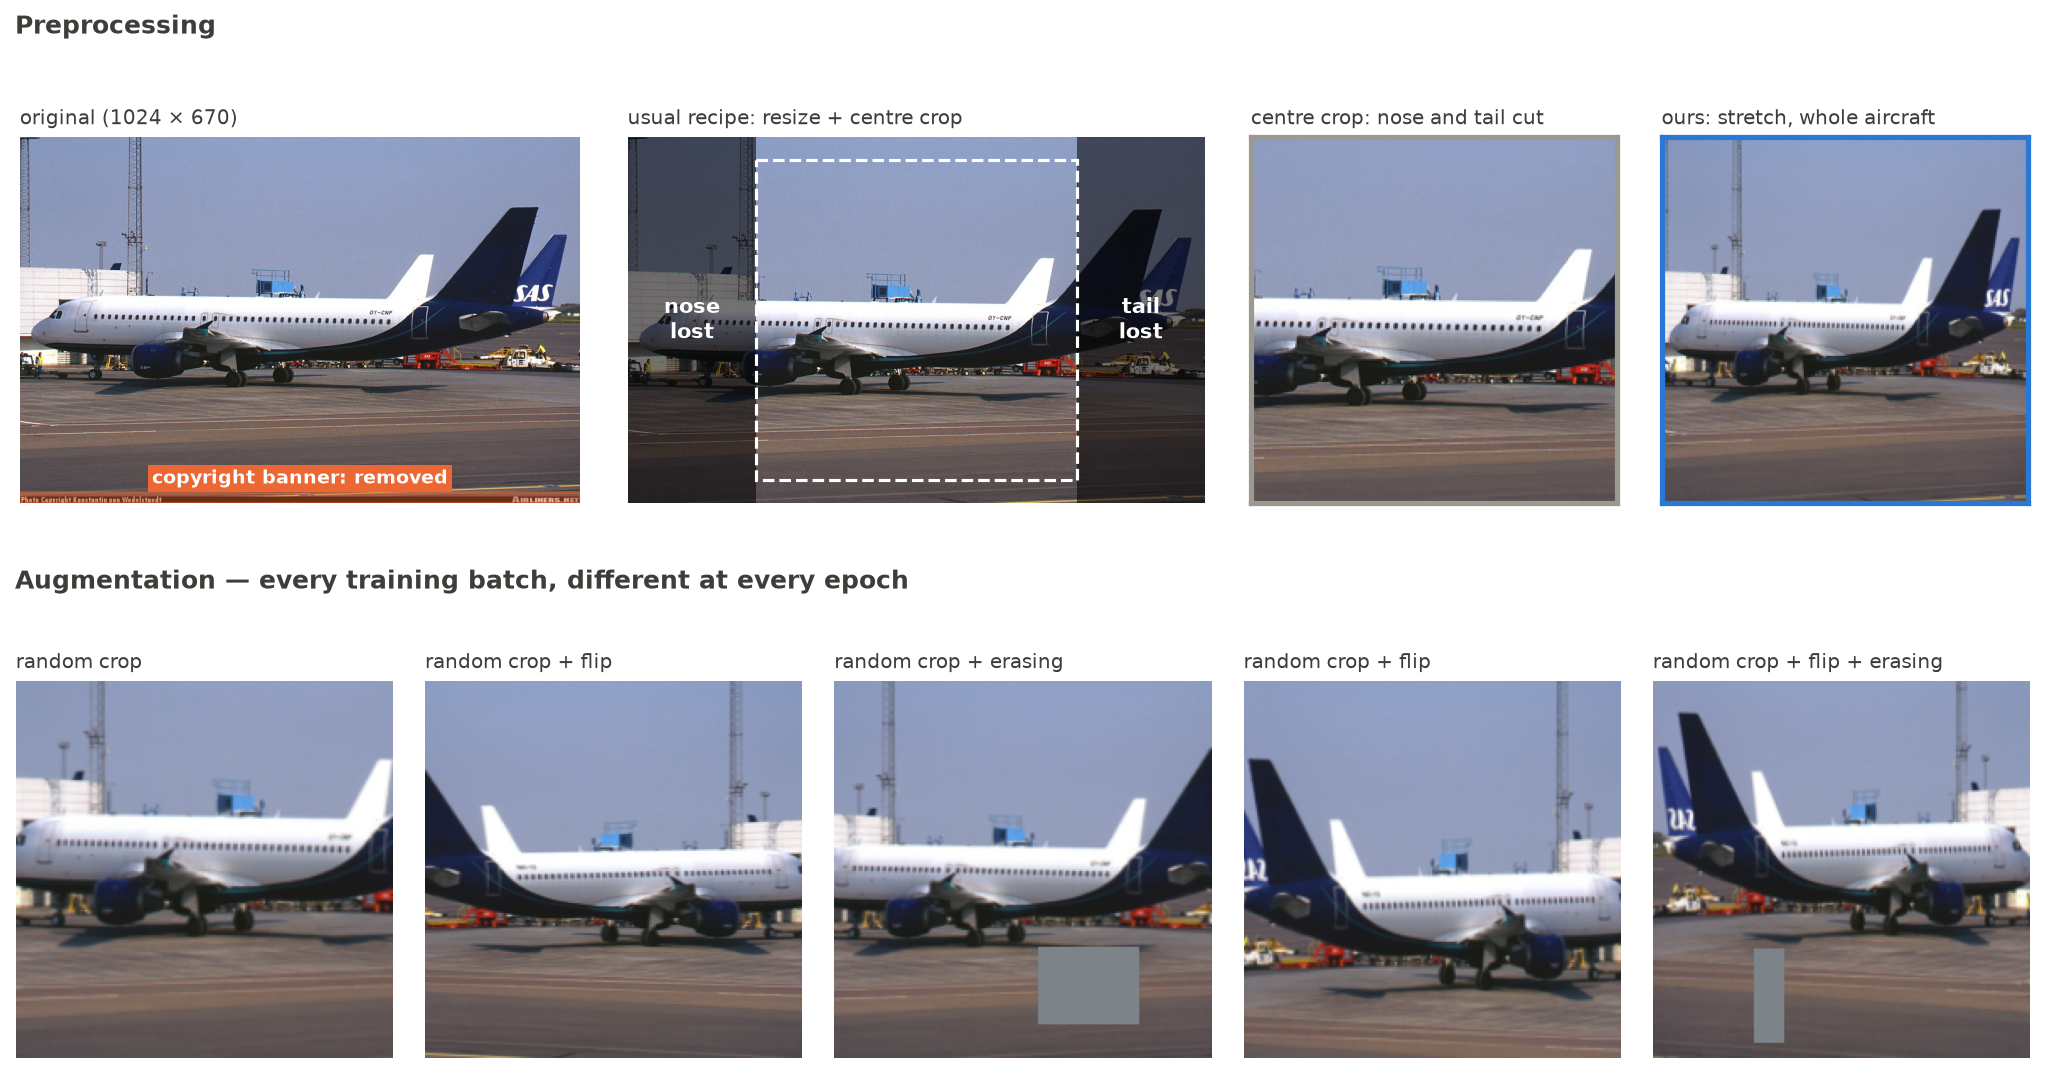

**Preprocessing** (top row). As the authors of the dataset require, we remove the 20-pixel copyright banner at the bottom of every image ("Please make sure to remove this banner when using the images to train and evaluate algorithms", <a href="https://www.robots.ox.ac.uk/~vgg/data/fgvc-aircraft/#format" target="_blank">FGVC-Aircraft</a>). We then resize the image to 224x224 *without* keeping the aspect ratio. Finally, as in VGG (Simonyan & Zisserman, 2015), we subtract the per-channel mean of the training split, and we also divide by the per-channel standard deviation, following the PyTorch convention (<a href="https://docs.pytorch.org/vision/stable/models.html" target="_blank">TorchVision, Models and pre-trained weights</a> and <a href="https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html">torchvision.models.resnet18</a>).

**Augmentation, on training batches only** (bottom row). Random resized crops and horizontal flips change scale and position while preserving the label: a mirrored aircraft is still the same aircraft. Then random erasing is added by the training recipe.

**Data loading.** The images are read and preprocessed on the fly by a `DataLoader`; the augmentation uses the
torchvision transforms `RandomResizedCrop`, `RandomHorizontalFlip` and `RandomErasing`. The dataset is read through
the torchvision class, which downloads it the first time a run is trained.

In [246]:
from functools import cache

N_CLASSES = 100  # FGVC-Aircraft, annotation_level="variant"
BANNER_PX = 20
IMAGENET_MEAN, IMAGENET_STD = (
    (0.485, 0.456, 0.406),
    (0.229, 0.224, 0.225),
)  # statistics the pretrained ResNet-18 expects


NUM_WORKERS = 4 if IN_COLAB else 0   # DataLoader workers; 0 locally (notebook classes cannot be pickled by spawn)


@cache
def load_split(split):
    # The torchvision dataset of one split, downloaded if needed.
    return datasets.FGVCAircraft(DATA_ROOT, split=split, annotation_level="variant", download=True)


def preprocess(img, img_size):
    # Crop the copyright banner and stretch the image to a square.
    img = img.crop((0, 0, img.width, img.height - BANNER_PX))
    return TF.resize(img, [img_size, img_size], antialias=True)


class AircraftSplit(Dataset):
    # One split read on the fly: preprocessed image -> transform -> (tensor, label).
    def __init__(self, split, img_size, transform):
        self.base, self.img_size, self.transform = load_split(split), img_size, transform
        self.split, self.classes = split, self.base.classes
        self.y = torch.tensor(self.base._labels)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, index):
        img, label = self.base[index]
        return self.transform(preprocess(img, self.img_size)), label

    def with_transform(self, transform):
        return AircraftSplit(self.split, self.img_size, transform)


@cache
def train_statistics(img_size):
    # Per-channel mean and standard deviation over every pixel of the training split.
    loader = DataLoader(AircraftSplit("train", img_size, T.ToTensor()), batch_size=256, num_workers=NUM_WORKERS)
    total, total_sq, n = torch.zeros(3, dtype=torch.float64), torch.zeros(3, dtype=torch.float64), 0
    for x, _ in tqdm(loader, desc="statistics of the training split"):
        x = x.double()
        total += x.sum(dim=(0, 2, 3))
        total_sq += (x**2).sum(dim=(0, 2, 3))
        n += x.shape[0] * x.shape[2] * x.shape[3]
    mean = total / n
    std = (total_sq / n - mean**2).sqrt()
    return tuple(mean.tolist()), tuple(std.tolist())


_DATA = {}


def get_data(img_size, imagenet_stats=False):
    # The three splits at one resolution, plus normalization statistics: measured on train only, or those of
    # ImageNet for the pretrained network. The splits are read with the evaluation transform (no augmentation).
    key = (img_size, imagenet_stats)
    if key not in _DATA:
        mean, std = (IMAGENET_MEAN, IMAGENET_STD) if imagenet_stats else train_statistics(img_size)
        evaluation = T.Compose([T.ToTensor(), T.Normalize(mean, std)])
        splits = {s: AircraftSplit(s, img_size, evaluation) for s in ("train", "val", "test")}
        _DATA[key] = dict(splits, mean=mean, std=std)
    return _DATA[key]


def train_transform(data, cfg):
    # Augmentation of the training images: random resized crop + flip (cfg["augment"]), random erasing.
    steps = []
    if cfg["augment"]:
        steps += [
            T.RandomResizedCrop(cfg["img_size"], scale=tuple(cfg["crop_scale"]), ratio=(3 / 4, 4 / 3), antialias=True),
            T.RandomHorizontalFlip(),
        ]
    steps += [T.ToTensor(), T.Normalize(data["mean"], data["std"])]
    if cfg["random_erasing"] > 0:
        steps.append(T.RandomErasing(p=cfg["random_erasing"], value=0))  # 0 is the mean of the normalized images
    return T.Compose(steps)


def batches(split, data, cfg, train):
    # Yields normalized (x, y) batches; train=True shuffles, drops the last partial batch and augments.
    if train:
        split = split.with_transform(train_transform(data, cfg))
    loader = DataLoader(
        split, batch_size=cfg["batch_size"] if train else 512, shuffle=train, drop_last=train, num_workers=NUM_WORKERS
    )
    for x, y in loader:
        yield x.to(DEVICE), y.to(DEVICE)

## The network

A single network class builds every network of the study from its configuration. In the figure, the components
added by a step of the roadmap have the colour of that step in the roadmap chart; $n_1, \dots, n_4$ are the
numbers of blocks per stage, varied in section 2:

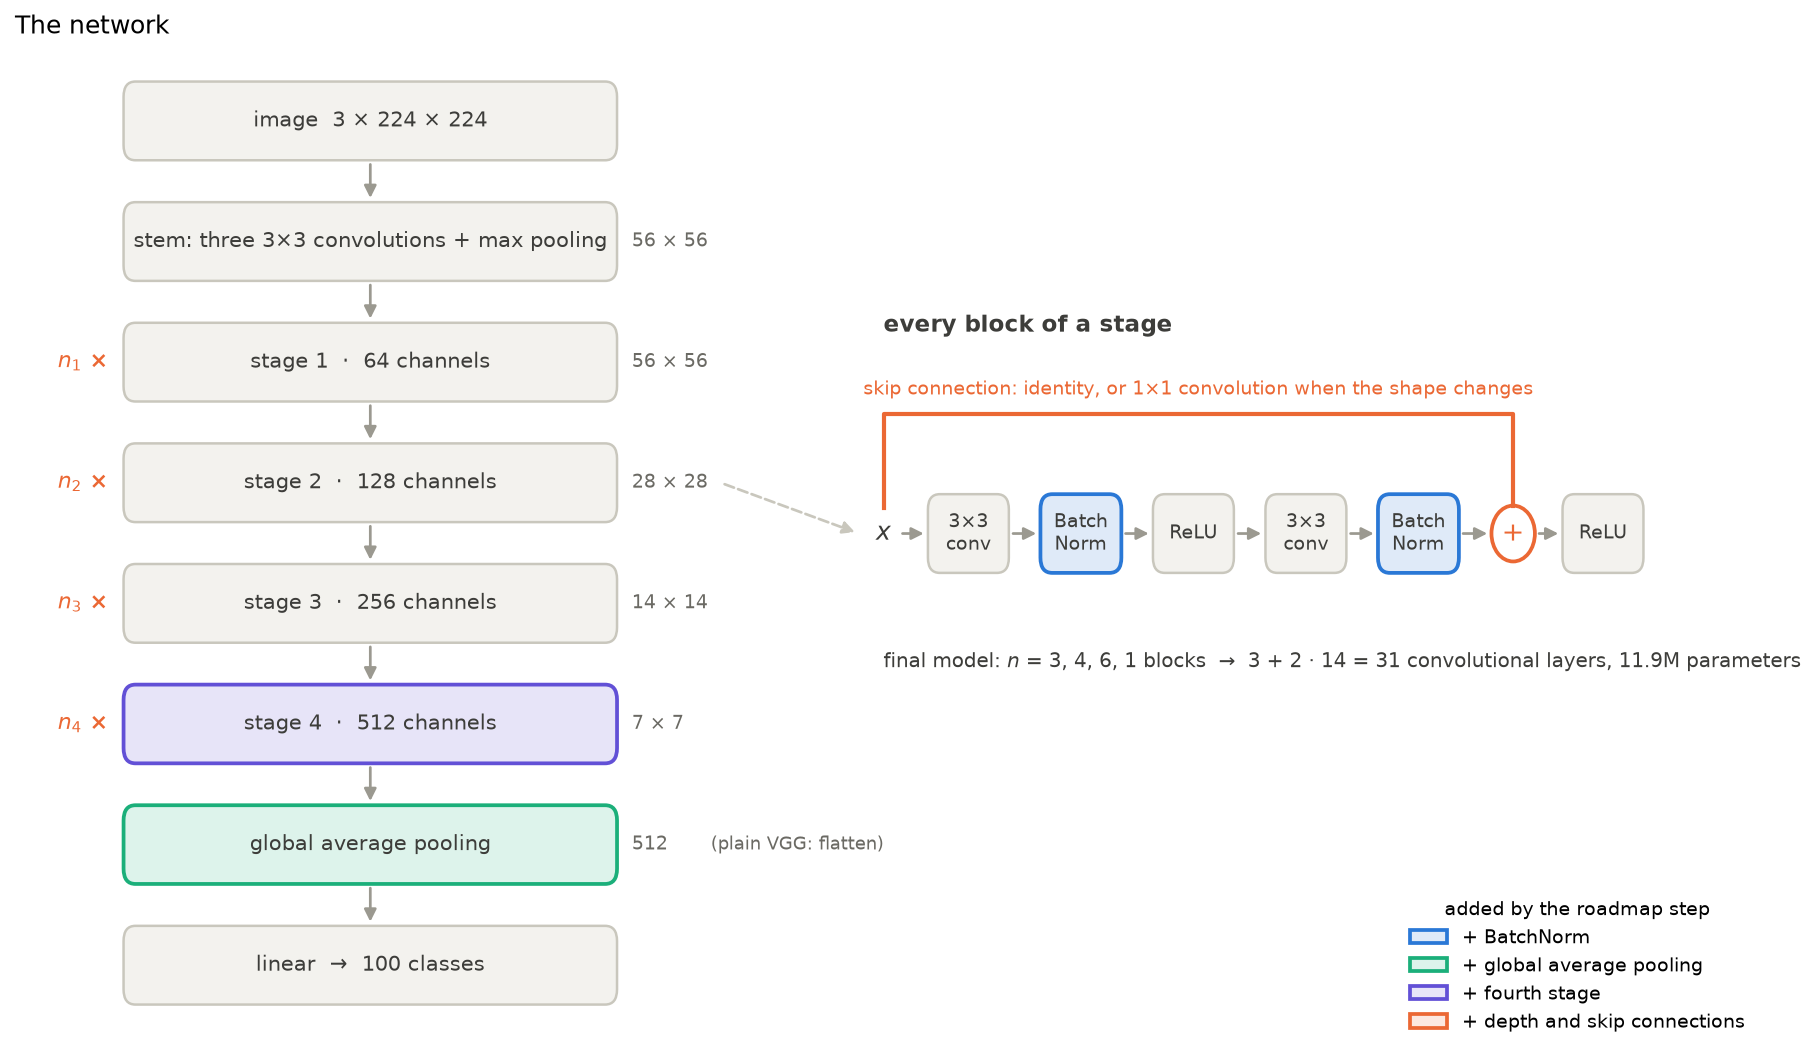

- **Stem**: three 3x3 convolutions (32, 32, 64 channels, the first with stride 2) and a 3x3 max-pool with stride 2,
  which reduce the resolution from 224x224 to 56x56, as in ResNet-C.
- **Stages**: up to four stages of identical blocks, with every stage after the first
  halving the resolution and doubling the number of channels. A block is two 3x3 convolutions, each followed by a ReLU.
- **BatchNorm** (optional): after every convolution, before the ReLU; the convolutions it follows have no bias.
- **Residual connections** (optional): the block adds its input to its output before the second ReLU. When the
  resolution or the number of channels changes, the input goes through a 1x1 convolution with BatchNorm (projection).
- **Classifier**: global average pooling followed by a linear layer, or (optional) a flatten layer followed by a linear
  layer.


In [247]:
def conv_bn(c_in, c_out, k, stride, bn):
    layers = [nn.Conv2d(c_in, c_out, k, stride=stride, padding=k // 2, bias=not bn)]
    if bn:
        layers.append(nn.BatchNorm2d(c_out))
    return nn.Sequential(*layers)


class Block(nn.Module):
    def __init__(self, c_in, c_out, stride, bn, residual):
        super().__init__()
        self.conv1 = conv_bn(c_in, c_out, 3, stride, bn)
        self.conv2 = conv_bn(c_out, c_out, 3, 1, bn)
        self.residual = residual
        if residual and (stride != 1 or c_in != c_out):
            self.skip = conv_bn(c_in, c_out, 1, stride, bn)  # projection
        else:
            self.skip = nn.Identity()

    def forward(self, x):
        out = self.conv2(F.relu(self.conv1(x)))
        if self.residual:
            out = out + self.skip(x)
        return F.relu(out)


class AircraftNet(nn.Module):
    def __init__(self, cfg, n_classes=100):
        super().__init__()
        bn = cfg["batchnorm"]
        c1, c2, c3 = cfg["stem"]
        self.stem = nn.Sequential(
            conv_bn(3, c1, 3, 2, bn),
            nn.ReLU(inplace=True),
            conv_bn(c1, c2, 3, 1, bn),
            nn.ReLU(inplace=True),
            conv_bn(c2, c3, 3, 1, bn),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(3, stride=2, padding=1),
        )
        layers, c_in = [], c3
        for stage, (c_out, n_blocks) in enumerate(zip(cfg["channels"], cfg["blocks"])):
            for b in range(n_blocks):
                stride = 2 if (b == 0 and stage > 0) else 1
                layers.append(Block(c_in, c_out, stride, bn, cfg["residual"]))
                c_in = c_out
        self.stages = nn.Sequential(*layers)

        if cfg["gap"]:
            self.head = nn.Sequential(
                nn.AdaptiveAvgPool2d(1),
                nn.Flatten(),
                nn.Dropout(cfg["dropout"]),
                nn.Linear(c_in, n_classes),
            )
        else:
            with torch.no_grad():  # size of the last feature map, for the flatten head
                s = self.stages(self.stem(torch.zeros(1, 3, cfg["img_size"], cfg["img_size"]))).shape
            self.head = nn.Sequential(
                nn.Flatten(),
                nn.Dropout(cfg["dropout"]),
                nn.Linear(s[1] * s[2] * s[3], n_classes),
            )

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.head(self.stages(self.stem(x)))


def build_model(cfg, n_classes=100):
    # The network of a configuration: our AircraftNet, or (Part 2) the ResNet-18 of PyTorch pretrained on ImageNet-1K
    # with its 1000-way classifier replaced by Dropout -> Linear(512, n_classes).
    if not cfg.get("pretrained", False):
        return AircraftNet(cfg, n_classes)
    model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Sequential(nn.Dropout(cfg["dropout"]), nn.Linear(model.fc.in_features, n_classes))
    return model


def count_params(model):
    return sum(p.numel() for p in model.parameters())


def count_gflops(model, img_size):
    # Multiply-adds of convolutions and linear layers for one image, x2 = FLOPs.
    macs = 0

    def hook(m, inp, out):
        nonlocal macs
        if isinstance(m, nn.Conv2d):
            macs += out[0].numel() * (m.in_channels // m.groups) * m.kernel_size[0] * m.kernel_size[1]
        elif isinstance(m, nn.Linear):
            macs += m.in_features * m.out_features

    handles = [m.register_forward_hook(hook) for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    with torch.no_grad():
        model.eval()(torch.zeros(1, 3, img_size, img_size))
    for h in handles:
        h.remove()
    return 2 * macs / 1e9

The final network of the study (residual, 3, 4, 6, 1 blocks per stage: 31 convolutional layers), with the number of
channels and the spatial resolution of every stage.

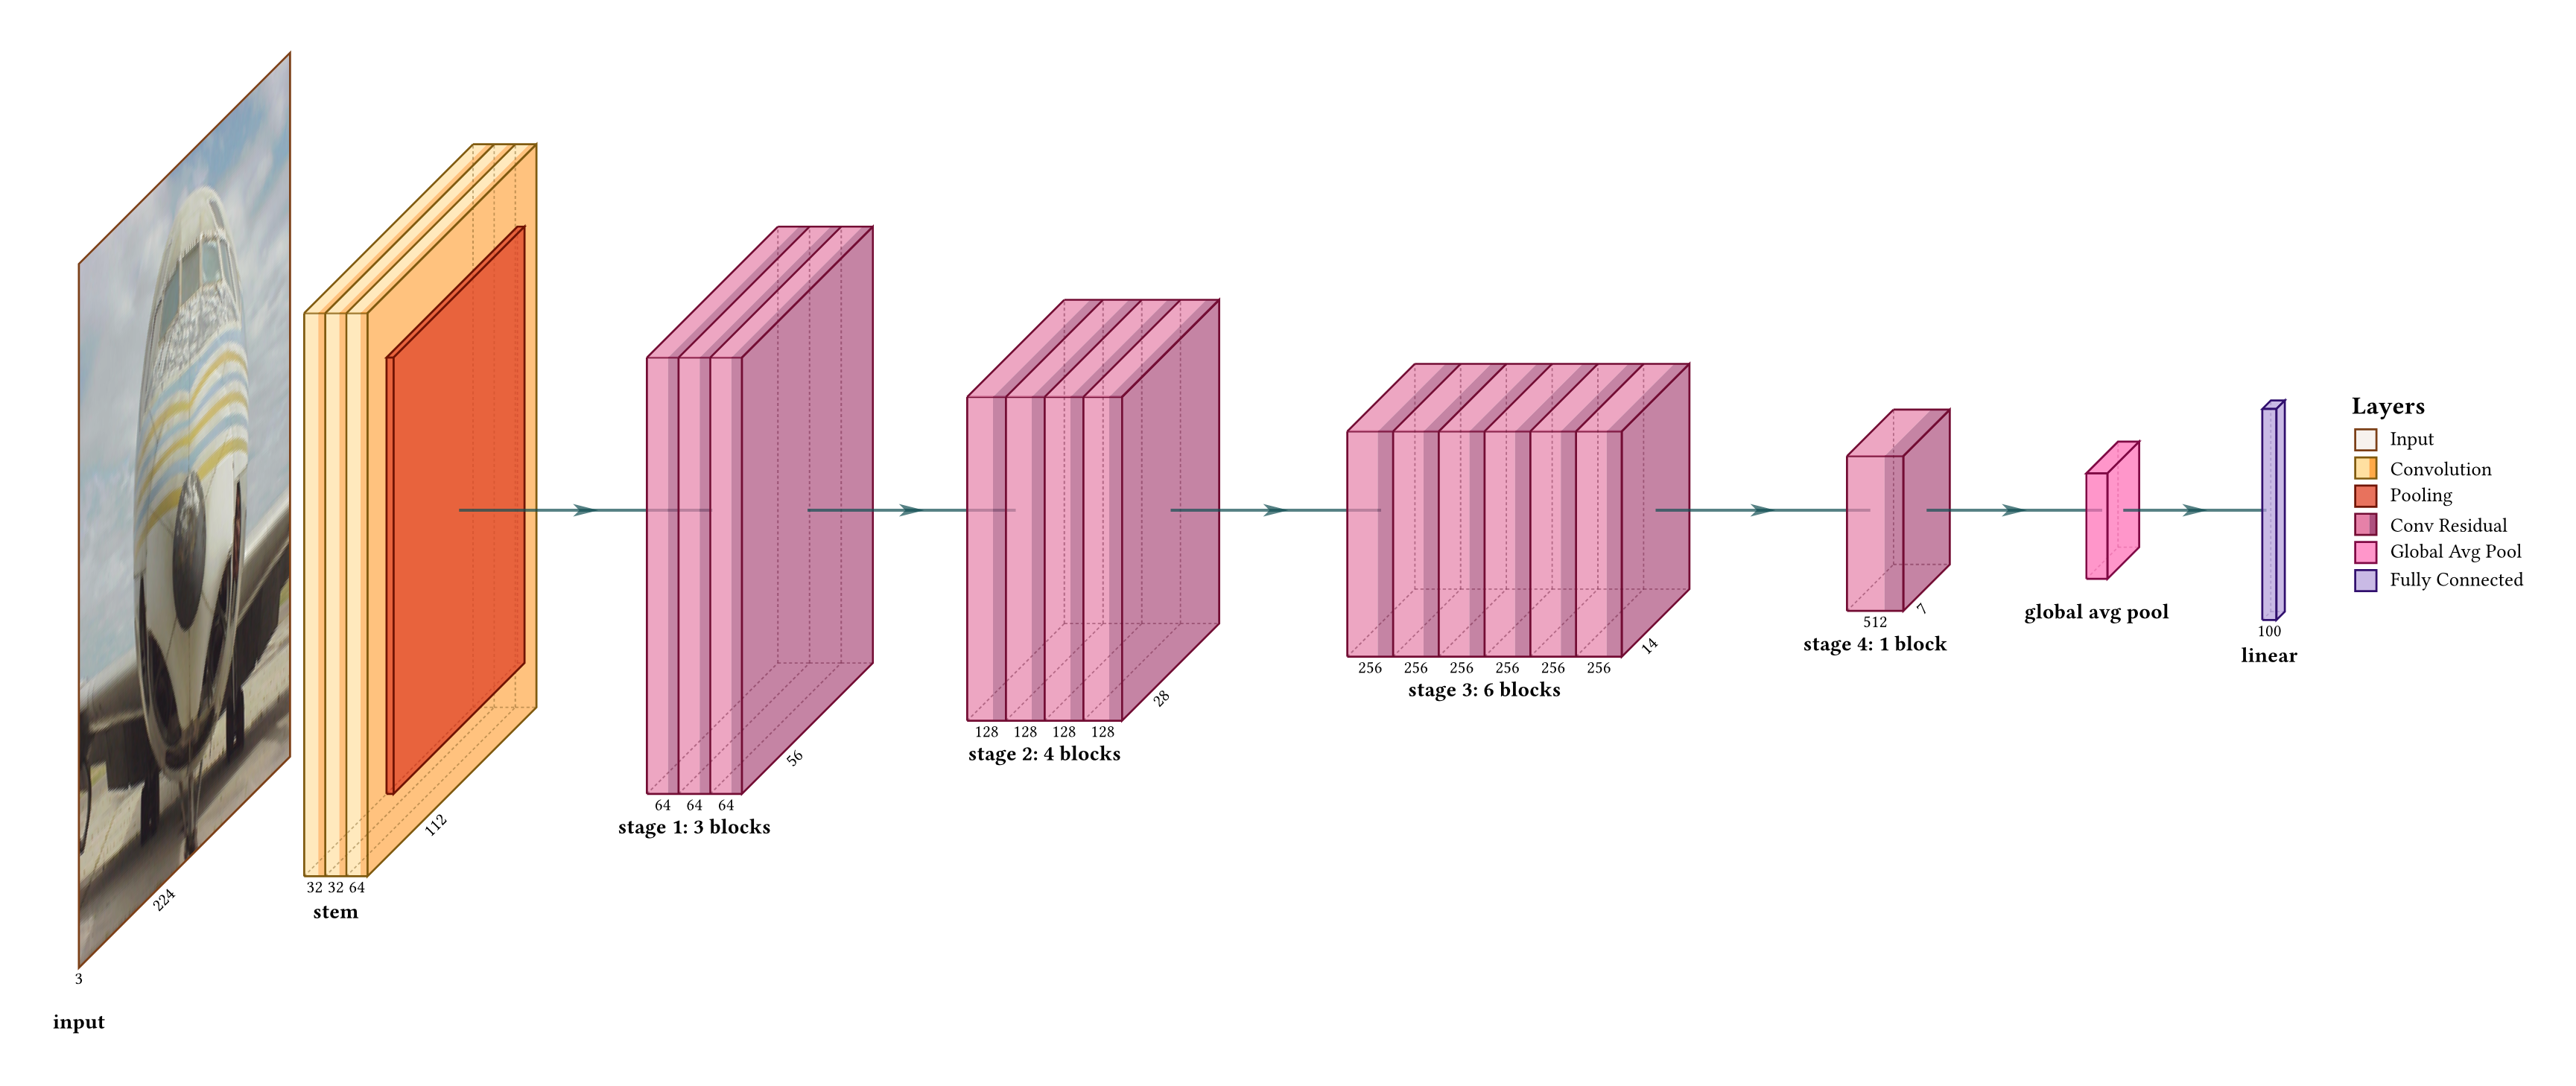

Size and cost of every network of the study.

In [248]:
rows = []
for name, over in LADDER + GRID:
    cfg = {**BASE, **over}
    m = AircraftNet(cfg, N_CLASSES)
    head = sum(p.numel() for p in m.head.parameters())
    rows.append(dict(run=name, params_M=count_params(m) / 1e6, head_share=head / count_params(m),
                     GFLOPs=count_gflops(m, cfg["img_size"]), convs=sum(isinstance(l, nn.Conv2d) for l in m.modules())))
pd.DataFrame(rows).set_index("run").style.format({"params_M": "{:.2f}", "head_share": "{:.2%}", "GFLOPs": "{:.2f}"})

,params_M,head_share,GFLOPs,convs
run,,,,
s0_vgg,6.23,80.58%,1.88,9
s1_bn,6.23,80.57%,1.88,9
s2_gap,1.24,2.08%,1.87,9
s3_aug,1.24,2.08%,1.87,9
s4_stage4,4.80,1.07%,2.22,11
plain_1111,4.80,1.07%,2.22,11
res_1111,4.98,1.03%,2.26,14
plain_2222,11.07,0.46%,4.07,19
res_2222,11.25,0.46%,4.11,22


## Training

- **Loss:** cross-entropy, with label smoothing where the recipe enables it.
- **Weight decay**, when enabled, applies to convolution and linear weights only, not to BatchNorm parameters and
  biases.
- **Model selection**: every run keeps the epoch with the highest validation accuracy, and the
  test split is evaluated once

In [ ]:
def make_optimizer(model, cfg):
    decay = [p for p in model.parameters() if p.ndim > 1]
    no_decay = [p for p in model.parameters() if p.ndim <= 1]
    return torch.optim.SGD([{"params": decay, "weight_decay": cfg["weight_decay"]},
                            {"params": no_decay, "weight_decay": 0.0}], lr=cfg["lr"], momentum=cfg["momentum"])


def lr_at(epoch, cfg):
    if cfg.get("schedule", "cosine") == "onecycle":
        up = max(round(0.3 * cfg["epochs"]), 1)
        low, high, end = cfg["lr"] / 25, cfg["lr"], cfg["lr"] / 1e4
        if epoch < up:
            return high + (low - high) * (1 + math.cos(math.pi * epoch / up)) / 2
        t = (epoch - up) / max(cfg["epochs"] - up, 1)
        return end + (high - end) * (1 + math.cos(math.pi * t)) / 2
    if epoch < cfg["warmup_epochs"]:
        return cfg["lr"] * (epoch + 1) / cfg["warmup_epochs"]
    progress = (epoch - cfg["warmup_epochs"]) / max(cfg["epochs"] - cfg["warmup_epochs"], 1)
    return cfg["lr"] * 0.5 * (1 + math.cos(math.pi * progress))


def train_epoch(model, opt, criterion, data, cfg):
    model.train()
    total_loss = torch.zeros((), device=DEVICE)
    correct = torch.zeros((), device=DEVICE)
    n = 0
    for x, y in batches(data["train"], data, cfg, train=True):
        logits = model(x)
        loss = criterion(logits, y)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        total_loss += loss.detach().float() * len(y)
        correct += (logits.argmax(1) == y).sum()
        n += len(y)
    return total_loss.item() / n, correct.item() / n


@torch.no_grad()
def evaluate(model, split, data, cfg, return_preds=False):
    model.eval()
    total_loss, correct, preds = 0.0, 0, []
    for x, y in batches(split, data, cfg, train=False):
        logits = model(x)
        total_loss += F.cross_entropy(logits, y, reduction="sum").item()
        p = logits.argmax(1)
        correct += (p == y).sum().item()
        if return_preds:
            preds.append(p.cpu())
    n = len(split)
    out = (total_loss / n, correct / n)
    return out + (torch.cat(preds).tolist(),) if return_preds else out


def fit(cfg, data):
    model = build_model(cfg, N_CLASSES).to(DEVICE)
    opt = make_optimizer(model, cfg)
    criterion = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"])
    hist = {k: [] for k in ("train_loss", "train_acc", "val_loss", "val_acc", "lr", "seconds")}
    best_acc, best_epoch, best_state, diverged = -1.0, 0, None, False

    for epoch in range(cfg["epochs"]):
        t0 = time.time()
        lr = lr_at(epoch, cfg)
        for g in opt.param_groups:
            g["lr"] = lr
        tr_loss, tr_acc = train_epoch(model, opt, criterion, data, cfg)
        if not math.isfinite(tr_loss):
            diverged = True
            print(f"  diverged at epoch {epoch + 1} (training loss {tr_loss})")
            break
        va_loss, va_acc = evaluate(model, data["val"], data, cfg)
        for k, v in zip(hist, (tr_loss, tr_acc, va_loss, va_acc, lr, time.time() - t0)):
            hist[k].append(v)
        if va_acc > best_acc:
            best_acc, best_epoch = va_acc, epoch + 1
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if epoch % 5 == 0 or epoch == cfg["epochs"] - 1:
            print(f"  ep {epoch + 1:3d} | lr {lr:.4f} | train loss {tr_loss:.3f} acc {tr_acc:.3f} "
                  f"| val loss {va_loss:.3f} acc {va_acc:.3f} | {hist['seconds'][-1]:.1f}s")

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, hist, best_epoch, diverged

## Experiment runner and stored runs

`run_experiment` trains one configuration (in `results/part1`, or in the directory given by `results_dir` for Part 2),
evaluates its best checkpoint on the test split and stores the configuration, the per-epoch curves and the test
predictions; a run whose result already exists with the same configuration is loaded instead of trained. The runs of
the roadmap, of the depth and residual comparison and of the recipe search were obtained by calling it for every
configuration at the three learning rates of the sweep (seed 42), and then with two more seeds at the best learning
rate. The seed-42 result is the best of three learning rates, hence slightly optimistic; the two other seeds are not.

All the stored runs (Part 1, 2A and 2B) are then read into a single table, one row per run, from which every section
selects its runs with `stored(experiment, network, variant, seed)`. The plotting helpers used in the rest of the
notebook follow.

In [250]:
# the keys that only describe AircraftNet: a pretrained run does not store them
SCRATCH_ONLY_KEYS = ("stem", "channels", "blocks", "batchnorm", "gap", "residual")


def run_experiment(name, group, results_dir=None, **overrides):
    # Trains one configuration, evaluates its best checkpoint on the test split and stores the run; a stored run with
    # the same configuration is loaded instead (unless RETRAIN).
    global _RUNS
    cfg = {**BASE, **overrides, "name": name, "group": group}
    if cfg.get("pretrained", False):  # the architecture keys of AircraftNet do not describe the pretrained ResNet-18
        cfg = {k: v for k, v in cfg.items() if k not in SCRATCH_ONLY_KEYS}
    out = (results_dir or RESULTS_DIR) / group / f'{name}_seed{cfg["seed"]}.json'
    if not RETRAIN and out.exists():
        run = json.loads(out.read_text())
        if run["config"] == json.loads(json.dumps(cfg)):  # same configuration (tuples stored as lists)
            return run
        print(f"{group}/{name}: the configuration changed since the stored run, training")

    print(f"### {group}/{name}")
    fix_random(cfg["seed"])
    data = get_data(cfg["img_size"], cfg.get("pretrained", False))
    t0 = time.time()
    model, hist, best_epoch, diverged = fit(cfg, data)
    if best_epoch:
        test_loss, test_acc, test_pred = evaluate(model, data["test"], data, cfg, return_preds=True)
    else:  # diverged before the first validation: there is no checkpoint to test
        test_loss, test_acc, test_pred = float("nan"), float("nan"), []
    run = dict(
        name=name, group=group, seed=cfg["seed"], config=cfg, history=hist,
        best_val_acc=max(hist["val_acc"], default=0.0), best_epoch=best_epoch,
        final_val_acc=hist["val_acc"][-1] if hist["val_acc"] else 0.0,
        final_train_acc=hist["train_acc"][-1] if hist["train_acc"] else 0.0,
        test_acc=test_acc, test_loss=test_loss, test_pred=test_pred, test_true=data["test"].y.tolist(),
        params=count_params(model), minutes=(time.time() - t0) / 60, diverged=diverged,
        device=torch.cuda.get_device_name() if DEVICE.type == "cuda" else str(DEVICE),
    )
    out.parent.mkdir(parents=True, exist_ok=True)
    out.write_text(json.dumps(run))
    _RUNS = None  # the table of the stored runs is read again on its next use
    print(f"{name}: best val {run['best_val_acc']:.3f} (epoch {best_epoch}) | test {test_acc:.3f}")
    return run


EXPERIMENTS = {  # results directory -> experiment: the extra seeds belong to the experiment of their configuration
    "depth_residual_seeds": "depth_residual", "tune_grid": "recipe", "tune_random": "recipe", "tune_seeds": "recipe",
    "s5_seeds": "s5_reg",
}
_RUNS = None  # the table of the stored runs, read on first use


def load_runs():
    # Every stored run as one row: experiment, network, variant of the configuration ("lr0.05" in a learning-rate
    # sweep, "lr0.05_wd0.005" or "cfg05" in the recipe search, "ep150" in the longer training), seed, accuracies and
    # hyperparameters. Run names are "{network}_{variant}_s{seed}"; the whole stored run is in the column `run`.
    networks = sorted((n for n, _ in LADDER + GRID), key=len, reverse=True)
    rows = []
    for path in sorted(p for d in (RESULTS_DIR, RESULTS_DIR_2A, RESULTS_DIR_2B) for p in d.glob("*/*.json")):
        r = json.loads(path.read_text())
        base = re.sub(r"_s\d+$", "", r["name"])  # the seed suffix of the extra seeds
        network = next((n for n in networks if base == n or base.startswith(n + "_")), base)
        config = {k: tuple(v) if isinstance(v, list) else v for k, v in r["config"].items()
                  if k not in ("name", "group", "seed")}
        rows.append(dict(config, experiment=EXPERIMENTS.get(path.parent.name, path.parent.name), network=network,
                         variant=base[len(network) + 1:], seed=r["seed"], val=r["best_val_acc"], test=r["test_acc"],
                         train=r["final_train_acc"], run=r))
    return pd.DataFrame(rows) if rows else pd.DataFrame(columns=["experiment", "network", "variant", "seed", "run"])


def stored(experiment, network=None, variant=None, seed=None):
    # The stored runs of one experiment, optionally of one network, variant and seed, ordered by seed.
    global _RUNS
    if _RUNS is None:
        _RUNS = load_runs()
    t = _RUNS[_RUNS.experiment == experiment]
    for column, value in (("network", network), ("variant", variant), ("seed", seed)):
        if value is not None:
            t = t[t[column] == value]
    return t.sort_values("seed", kind="stable")


def best_run(t):
    # The run with the highest validation accuracy (the first one on ties).
    return t.iloc[int(np.argmax(t.val.to_numpy()))]


def best_lr(experiment, network):
    # The seed-42 run of a network at the learning rate that won its sweep; None until every learning rate is trained.
    sweep = stored(experiment, network, seed=SEEDS[0])
    return best_run(sweep) if len(sweep) == len(LR_SWEEP) else None


def at_best_lr(experiment, network):
    # Every seed of a network at the learning rate that won its sweep (none until the sweep is complete).
    best = best_lr(experiment, network)
    return stored(experiment, network, best.variant) if best is not None else stored(experiment, network).iloc[:0]


def best_confirmed(confirmed_runs):
    # (key, runs) of the configuration with the best mean validation accuracy among those trained with every seed.
    done = {k: t for k, t in confirmed_runs.items() if len(t) == len(SEEDS)}
    if not done:
        return None
    best = max(done, key=lambda k: done[k].val.mean())
    return best, done[best]


def run_overrides(run):
    # The overrides that reproduce a stored run (everything but its name, group and seed).
    return {k: v for k, v in run["config"].items() if k not in ("name", "group", "seed")}

In [251]:
# Readable names for tables and plots; the stored run names are unchanged
DISPLAY = {
    "s0_vgg": "plain VGG", "s1_bn": "+ BatchNorm", "s2_gap": "+ global average pooling",
    "s3_aug": "+ crop and flip", "s4_stage4": "+ fourth stage",
    "plain_1111": "plain, 11 layers", "res_1111": "residual, 11 layers",
    "plain_2222": "plain, 19 layers", "res_2222": "residual, 19 layers",
    "plain_3461": "plain, 31 layers", "res_3461": "residual, 31 layers",
}


def label(name):
    # Readable name of a network, a roadmap step or a recipe configuration.
    if name in DISPLAY:
        return DISPLAY[name]
    m = re.fullmatch(r"cfg(\d+)", name)
    if m:
        return f"configuration {int(m.group(1))}"
    m = re.fullmatch(r"lr([\d.e-]+)_wd([\d.e-]+)", name)
    if m:
        return f"learning rate {m.group(1)}, weight decay {m.group(2)}"
    return name


# Categorical colours in a fixed order (one per run inside a plot)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=COLORS), "lines.linewidth": 2,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})


def summary(runs):
    # One row per run (single seed).
    rows = [{"network": label(n), "learning rate": r["config"]["lr"], "parameters (M)": r["params"] / 1e6,
             "best validation": r["best_val_acc"], "best epoch": r["best_epoch"],
             "final training": r["final_train_acc"], "train − validation gap": r["final_train_acc"] - r["final_val_acc"],
             "test": r["test_acc"], "minutes": r["minutes"]}
            for n, r in runs.items()]
    return pd.DataFrame(rows).set_index("network").style.format(
        {"learning rate": "{:g}", "parameters (M)": "{:.2f}", "best validation": "{:.3f}", "final training": "{:.3f}",
         "train − validation gap": "{:+.3f}", "test": "{:.3f}", "minutes": "{:.1f}"})


def seed_summary(groups):
    # One row per configuration, mean ± std over the seeds. groups: {name: stored runs of its seeds}
    rows = [{"network": label(name), "learning rate": t.lr.iloc[0], "seeds": len(t),
             "parameters (M)": t.run.iloc[0]["params"] / 1e6,
             "validation (mean)": t.val.mean(), "validation (std)": t.val.std(),
             "test (mean)": t.test.mean(), "test (std)": t.test.std(), "final training (mean)": t.train.mean()}
            for name, t in groups.items() if len(t)]
    return pd.DataFrame(rows).set_index("network").style.format(
        {"learning rate": "{:g}", "parameters (M)": "{:.2f}", "validation (mean)": "{:.3f}",
         "validation (std)": "{:.3f}", "test (mean)": "{:.3f}", "test (std)": "{:.3f}",
         "final training (mean)": "{:.3f}"})


def plot_curves(runs, title=""):
    # Validation accuracy, validation loss (plain CE) and training accuracy against the epoch.
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    for i, (name, r) in enumerate(runs.items()):
        h = r["history"]
        ep = range(1, len(h["val_acc"]) + 1)
        c = COLORS[i % len(COLORS)]
        axes[0].plot(ep, h["val_acc"], color=c, label=label(name))
        if r["best_epoch"]:
            axes[0].plot(r["best_epoch"], r["best_val_acc"], "o", color=c, markersize=7)
        axes[1].plot(ep, h["val_loss"], color=c, label=label(name))
        axes[2].plot(ep, h["train_acc"], color=c, label=label(name))
    for ax, t in zip(axes, ("validation accuracy (dot = best epoch)", "validation loss (cross-entropy)",
                            "training accuracy")):
        ax.set_title(t); ax.set_xlabel("epoch")
    axes[0].legend(fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

## 1. From a plain VGG to a residual network: a roadmap

Each step adds one change to the previous one and is trained at three learning rates (one seed). What we expect:

- **A plain VGG** with three stages and a flatten classifier.
- **+ BatchNorm** should make optimization better behaved and more tolerant to the learning rate.
- **+ global average pooling** removes the 5M-weight classifier.
- **+ crop and flip** show a different version of every image at every epoch, so the training set can no longer be
  memorized exactly.
- **+ a fourth stage** adds capacity and receptive field once the network is regularized.

### Results

Each step at its best learning rate; the curves show validation accuracy (dot = best epoch), validation loss and
training accuracy.

,learning rate,parameters (M),best validation,best epoch,final training,train − validation gap,test,minutes
network,,,,,,,,
plain VGG,0.01,6.23,0.185,29,1.000,+0.815,0.189,0.6
+ BatchNorm,0.01,6.23,0.302,37,1.000,+0.699,0.299,0.7
+ global average pooling,0.1,1.24,0.435,46,1.000,+0.567,0.440,0.7
+ crop and flip,0.1,1.24,0.477,66,0.947,+0.472,0.477,0.7
+ fourth stage,0.05,4.80,0.526,70,0.980,+0.454,0.507,0.8


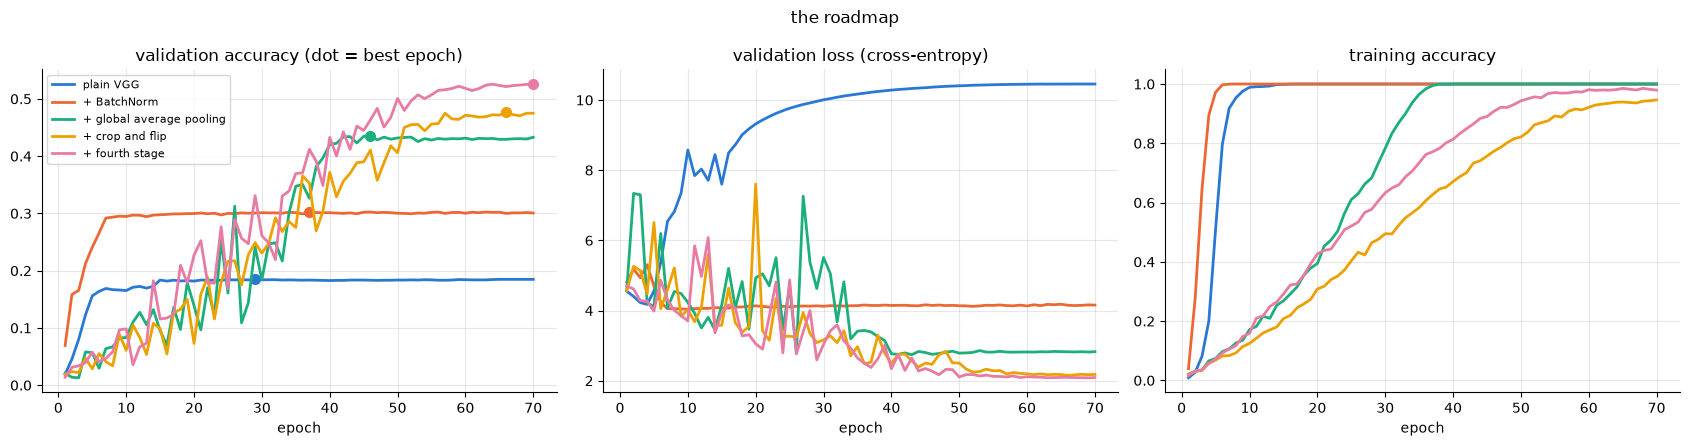

In [252]:
steps = {n: best_lr("ladder", n) for n, _ in LADDER}
steps = {n: r.run for n, r in steps.items() if r is not None}
if steps:
    display(summary(steps))

    plot_curves(steps, "the roadmap")

**Every step improves the network**

The first three networks reach **100% training accuracy**: they memorize the training
set. The plain VGG does it very quickly in the early epochs, after which its validation loss *rises* while its training loss goes to zero. BatchNorm and global average pooling make the memorizing network generalize better, but do not stop the memorization of the training dataset. Augmentation does: once crop and flip are added, the training accuracy stays below 100% and the gap between training and validation accuracy shrinks.



### Sensitivity to the learning rate

Best validation accuracy of every step at each learning rate.

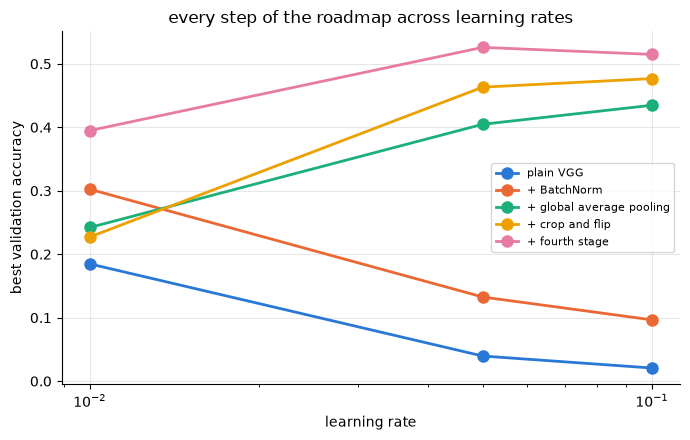

In [253]:
if len(stored("ladder")):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for i, (name, _) in enumerate(LADDER):
        swept = stored("ladder", name, seed=SEEDS[0]).sort_values("lr")
        if len(swept):
            ax.plot(swept.lr, swept.val, "o-", color=COLORS[i], label=label(name), markersize=8)
    ax.set_xscale("log"); ax.set_xlabel("learning rate"); ax.set_ylabel("best validation accuracy")
    ax.set_title("every step of the roadmap across learning rates"); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

A single learning rate for every step would have penalized some of the networks: this is why every configuration is compared at its own best

**At this point the target accuracy for this part** (~50%) is satisfied, but since with the use of augmentation and the fourth stage the network was still improving we decided to go further and explore wheter **more depth, residual connections and a tuned training recipe** could benefit overall.

## 2. Depth and residual connections

We experiment **identical plain and residual networks at increasing depth**. All six networks are the last network of the roadmap with a different number of blocks per stage, with and without skip connections:

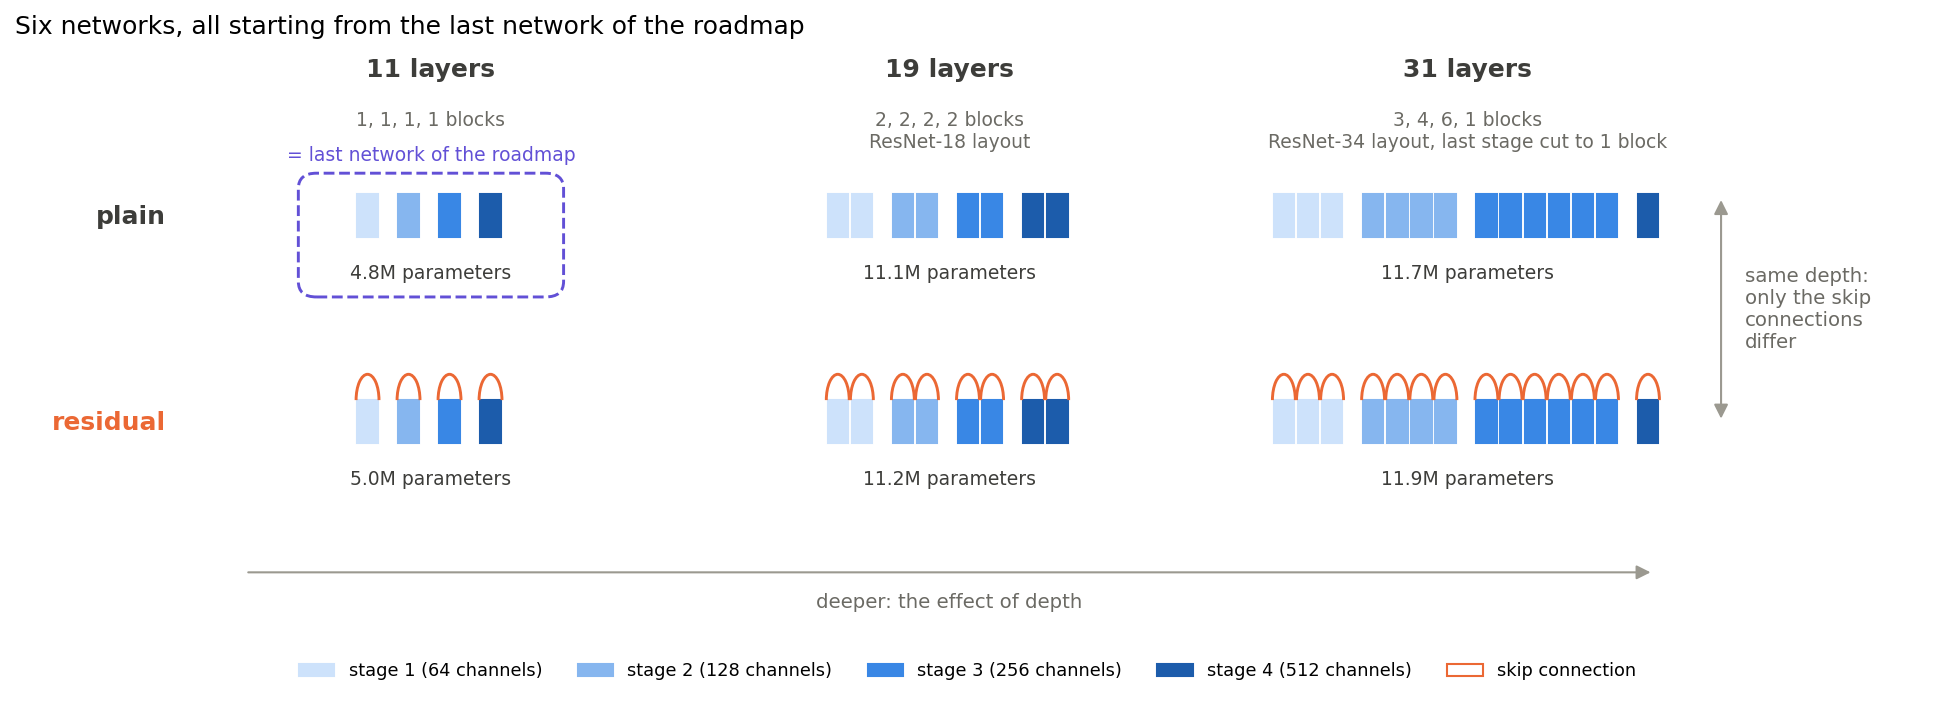


- **one block per stage**: 11 convolutional layers, the last network of the roadmap itself
- **two blocks per stage**: 19 layers, the stage layout of ResNet-18
- **3, 4, 6 and 1 blocks**: 31 layers,the layout of ResNet-34 with one block in the last stage

Within a depth, the two networks differ only by the skip connections.

### Results

The six networks with their validation accuracy (mean ± standard deviation over three seeds) and training accuracy;
then the same numbers against depth: left validation, right training accuracy.

,learning rate,seeds,parameters (M),validation (mean),validation (std),test (mean),test (std),final training (mean)
network,,,,,,,,
"plain, 11 layers",0.05,3,4.80,0.513,0.011,0.501,0.014,0.984
"residual, 11 layers",0.1,3,4.98,0.469,0.004,0.460,0.004,0.994
"plain, 19 layers",0.05,3,11.07,0.559,0.014,0.551,0.012,0.975
"residual, 19 layers",0.05,3,11.25,0.522,0.012,0.519,0.003,0.991
"plain, 31 layers",0.01,3,11.74,0.476,0.014,0.482,0.013,0.919
"residual, 31 layers",0.05,3,11.91,0.546,0.003,0.545,0.008,0.987


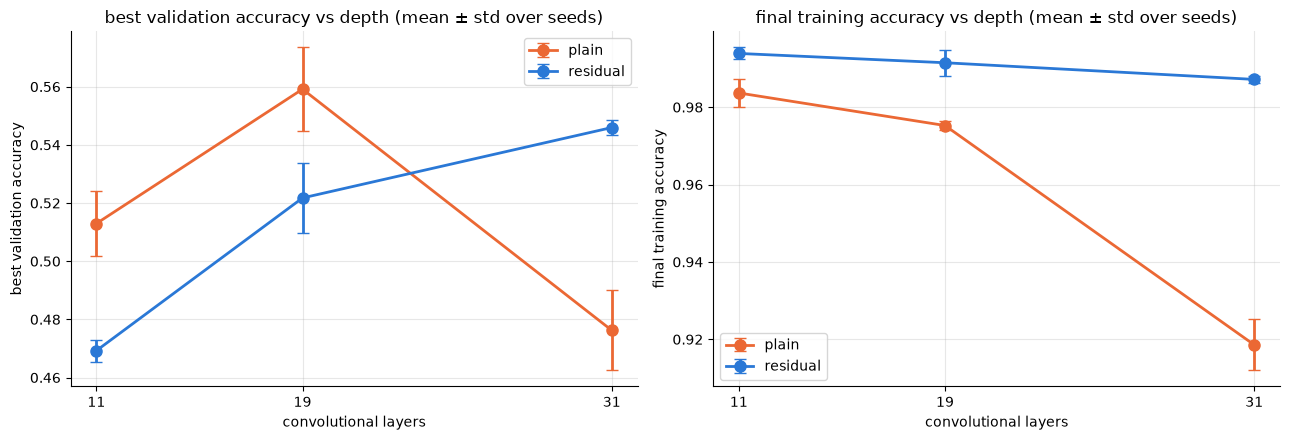

In [254]:
grid_runs = {n: at_best_lr("depth_residual", n) for n, _ in GRID}
grid_runs = {n: t for n, t in grid_runs.items() if len(t)}
if grid_runs:
    display(seed_summary(grid_runs))

    convs = {n: 3 + 2 * sum(cast("tuple[int, ...]", dict(GRID)[n]["blocks"])) for n in grid_runs}
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for kind, kind_label, c in (("plain", "plain", COLORS[1]), ("res", "residual", COLORS[0])):
        names = [n for n in grid_runs if n.startswith(kind + "_")]
        if not names:
            continue
        for ax, key in zip(axes, ("val", "train")):
            ax.errorbar([convs[n] for n in names], [grid_runs[n][key].mean() for n in names],
                        yerr=[np.nan_to_num(grid_runs[n][key].std()) for n in names],
                        fmt="o-", color=c, capsize=4, markersize=8, label=kind_label)
    for ax, t in zip(axes, ("best validation accuracy", "final training accuracy")):
        ax.set_xlabel("convolutional layers"); ax.set_ylabel(t); ax.set_xticks(sorted(set(convs.values())))
        ax.set_title(f"{t} vs depth (mean ± std over seeds)"); ax.legend()
    plt.tight_layout(); plt.show()

**Degradation.** From 19 to 31 layers the plain network degrades its validation accuracy, and its *training* accuracy
drops too: the deeper plain network is harder to optimize as we saw in lecture 5.
The residual network improves at every depth and keeps fitting its training set: skip
connections make depth usable.

**Shallow networks.** At 11 and 19 layers the residual networks are about 4 points worse than the plain ones, well beyond the seed noise. This is not an optimization problem: they fit their training set slightly better, so they lose accuracy on unseen images, not on the training set. At these depths a plain network is still easy to optimize, so skip connections bring no benefit. We expect regularization to help the residual networks more than the plain ones.



## 3. The training recipe

We regularize the three best networks of the previous experiment and tune their training recipe:

- **Weight decay** penalizes large weights.
- **Label smoothing**.
- **Dropout** before the classifier, between global pooling and the last linear layer.
- **Random erasing** hides a random rectangle of the image.
- **Minimum crop area** of the random resized crop: smaller crops show parts of the aircraft at a larger scale.
- **One-cycle schedule**: the learning rate rises over the first 30% of training, then decays to almost zero.

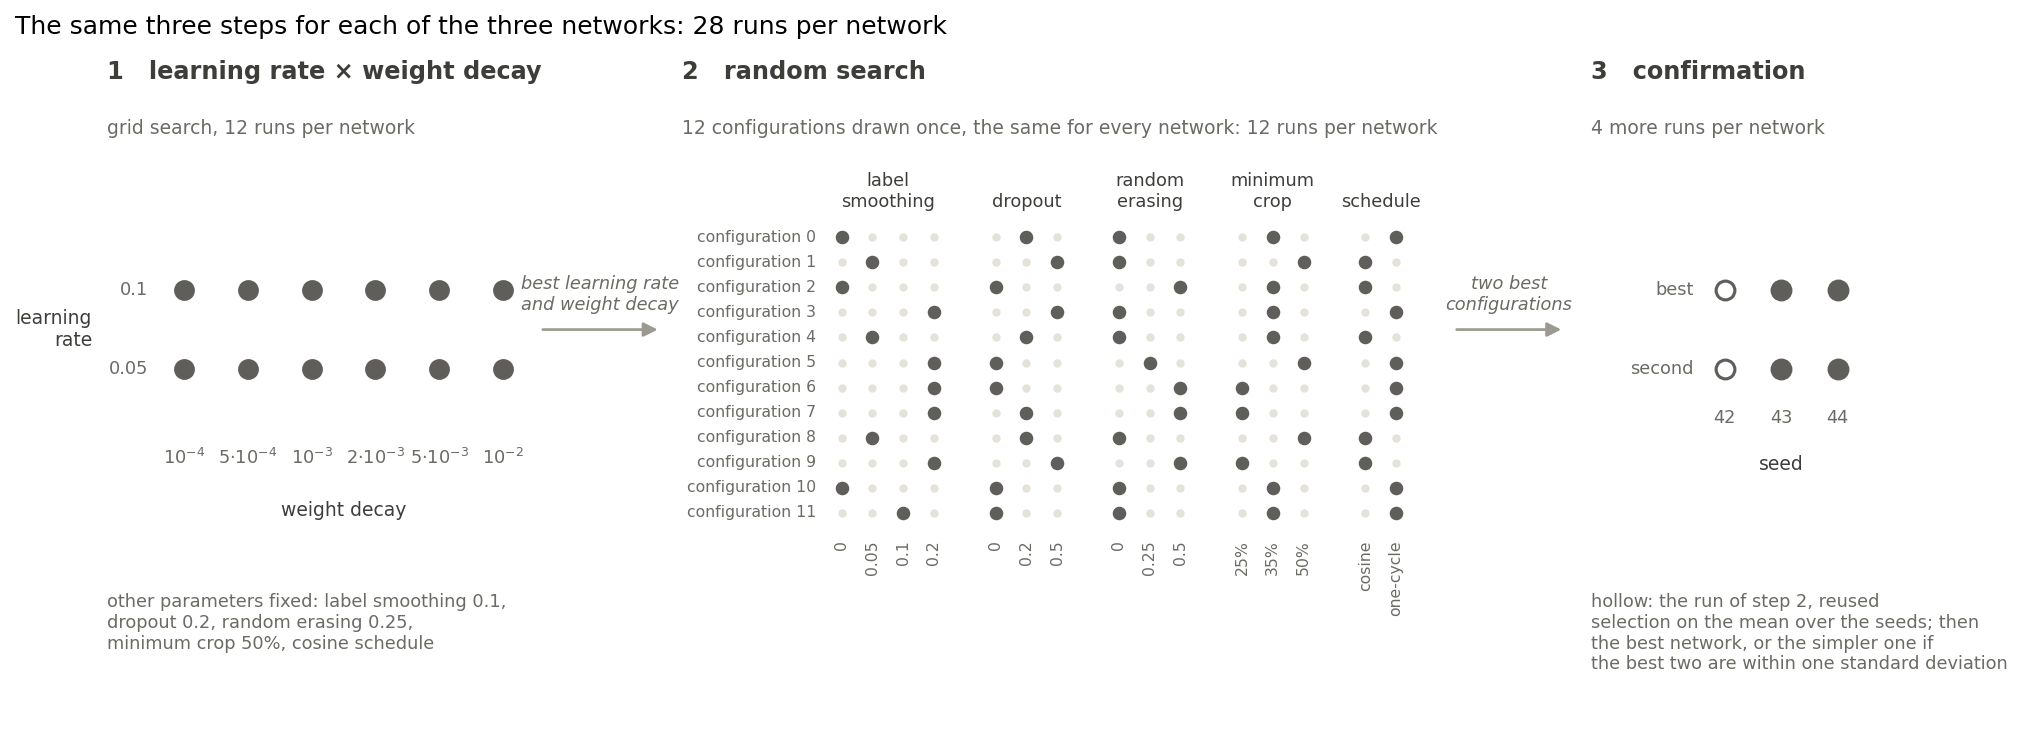

We tune the recipe in three steps, following a grid and random search, as seen in lecture 6:

1. **Grid search on learning rate x weight decay**, the two most influential parameters, log-spaced, with the other
   parameters fixed.
2. **Random search** on the other five parameters, at the best learning rate and weight
   decay of each network: a full grid would require 216 runs per network, so we draw 12 configurations once and
   train the same 12 on every network.
3. **Confirmation with seeds**: the best of many single runs is partly the luckiest, so the two best configurations of
   each network are retrained with two more seeds and compared on the mean.

**Selection rule.** The best configuration of each network by mean validation accuracy, then the best network, or
the simpler one if the best two are within one standard deviation.

In [255]:
# The selection rule, and the networks of the grid that enter the recipe search.

def finalists(n=TUNE_N):
    # The n networks of the grid with the highest mean validation accuracy over the seeds.
    done = {name: at_best_lr("depth_residual", name) for name, _ in GRID}
    if any(len(t) < len(SEEDS) for t in done.values()):
        return None
    return sorted(done, key=lambda name: -done[name].val.mean())[:n]


def simplicity(name):
    # Sort key: fewer blocks first, then plain before residual.
    over = dict(GRID)[name]
    return (sum(cast("tuple[int, ...]", over["blocks"])), over["residual"])


def select(runs_by_net, prefix="", verbose=True):
    # The selection rule: highest mean validation accuracy over the seeds; if the best two are within one standard
    # deviation of each other, the simpler network. Returns (ranked names, selected name).
    ranked = sorted(runs_by_net, key=lambda n: -runs_by_net[n].val.mean())
    first, second = ranked[0], ranked[1]
    diff = runs_by_net[first].val.mean() - runs_by_net[second].val.mean()
    noise = max(runs_by_net[first].val.std(), runs_by_net[second].val.std())
    selected = first if diff > noise else min((first, second), key=simplicity)
    if verbose:
        for n in ranked:
            t = runs_by_net[n]
            print(f"{label(n):20s} {prefix}validation {t.val.mean():.3f} ± {t.val.std():.3f} | "
                  f"test {t.test.mean():.3f} ± {t.test.std():.3f} | train {t.train.mean():.3f}")
        print(f"-> {label(first)}: better by {diff:.3f}, more than one standard deviation ({noise:.3f})" if diff > noise
              else f"-> a tie ({diff:.3f} <= {noise:.3f}): the simpler network, {label(selected)}")
    return ranked, selected

In [256]:
# The recipe search of one network: grid of learning rate x weight decay, random configurations, confirmation with seeds.

def search_runs(name):
    # The seed-42 runs of the recipe search of one network: grid points ("lr…_wd…") and random configurations ("cfg…").
    return stored("recipe", name, seed=SEEDS[0])


def confirmed(name):
    # {variant: runs over the seeds} for the TOP_K best configurations of the search of one network.
    top = search_runs(name).sort_values("val", ascending=False, kind="stable").variant[:TOP_K]
    return {v: stored("recipe", name, v) for v in top}


def best_tuned(name):
    # (variant, runs over the seeds) of the best configuration of the recipe search of one network.
    return best_confirmed(confirmed(name))

### Step 1 — learning rate and weight decay

Best validation accuracy of every point of the grid (seed 42), one panel per network; the ring marks the best point.

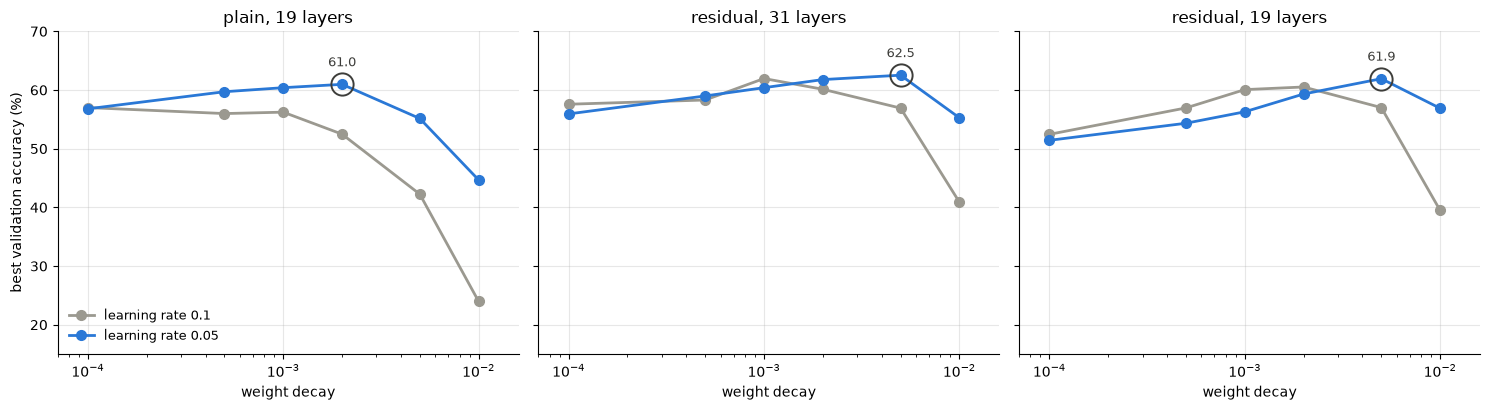

In [257]:
names = finalists(TUNE_N) or []
if names and len(stored("recipe")):
    fig, axes = plt.subplots(1, len(names), figsize=(15, 4.2), sharey=True)
    for ax, name in zip(axes, names):
        grid = search_runs(name).set_index("variant").val
        points = []
        for lr, c in zip(TUNE_LRS, ("#9b9990", COLORS[0])):
            acc = [100 * grid.get(f"lr{lr:g}_wd{wd:g}", np.nan) for wd in TUNE_WDS]
            ax.plot(TUNE_WDS, acc, "o-", color=c, lw=2, markersize=7, label=f"learning rate {lr:g}")
            points += zip(TUNE_WDS, acc)
        wd, acc = max(points, key=lambda p: np.nan_to_num(p[1]))
        ax.plot(wd, acc, "o", markersize=16, markerfacecolor="none", markeredgecolor="#3d3d3a", markeredgewidth=1.4)
        ax.annotate(f"{acc:.1f}", (wd, acc), xytext=(0, 13), textcoords="offset points", ha="center", fontsize=9.5,
                    color="#3d3d3a")
        ax.set_xscale("log"); ax.set_xlim(7e-5, 1.6e-2); ax.set_ylim(15, 70)
        ax.set_title(label(name)); ax.set_xlabel("weight decay")
    axes[0].set_ylabel("best validation accuracy (%)"); axes[0].legend(loc="lower left", fontsize=9, frameon=False)
    plt.tight_layout(); plt.show()

Accuracy increases with weight decay **for both residual networks**.

The optimum lies inside the grid for every network, so the range is wide enough. 

The residual networks, which fit their training set more easily, need the stronger regularization. With strong weight decay, a learning rate of 0.05 is better than 0.1.

### Step 2 — random search

Every configuration on every network (seed 42), sorted by the mean over the networks; in the plot every configuration is a
line through its parameter values, ending at its mean accuracy over the three networks (dark blue: the best configuration, light blue: the second best).

,label smoothing,dropout,random erasing,minimum crop,schedule,"plain, 19 layers","residual, 31 layers","residual, 19 layers",mean
configuration,,,,,,,,,
configuration 5,0.200000,0.000000,0.250000,0.500000,onecycle,0.618,0.644,0.647,0.636
configuration 11,0.100000,0.000000,0.000000,0.350000,onecycle,0.615,0.651,0.622,0.629
configuration 8,0.050000,0.200000,0.000000,0.500000,cosine,0.593,0.630,0.627,0.617
configuration 10,0.000000,0.000000,0.000000,0.350000,onecycle,0.595,0.633,0.616,0.615
configuration 0,0.000000,0.200000,0.000000,0.350000,onecycle,0.603,0.629,0.611,0.614
configuration 3,0.200000,0.500000,0.000000,0.350000,onecycle,0.598,0.612,0.623,0.611
configuration 1,0.050000,0.500000,0.000000,0.500000,cosine,0.586,0.605,0.611,0.600
configuration 4,0.050000,0.200000,0.000000,0.350000,cosine,0.559,0.624,0.606,0.596
configuration 7,0.200000,0.200000,0.500000,0.250000,onecycle,0.559,0.546,0.566,0.557


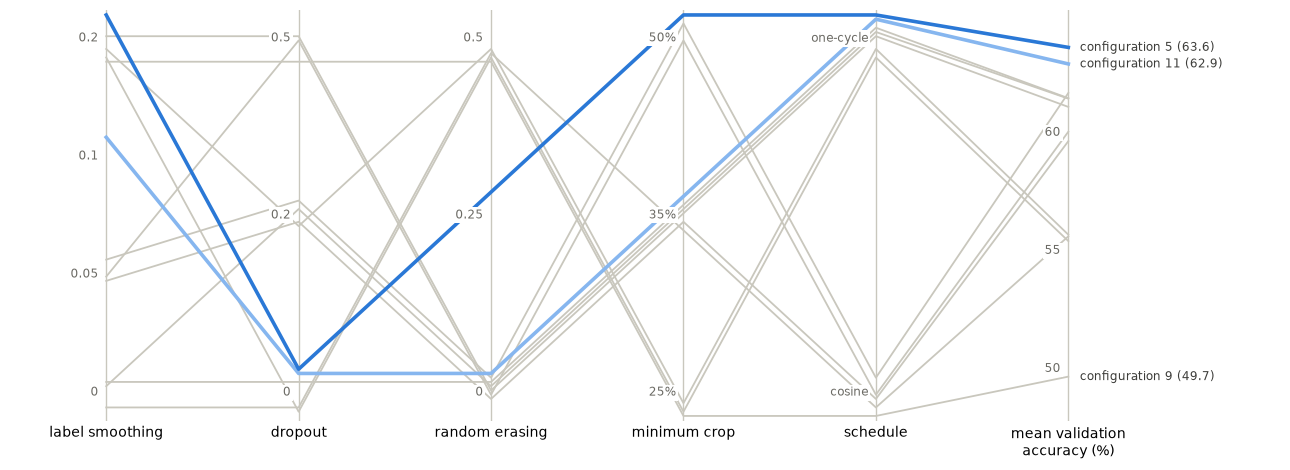

In [258]:
search = stored("recipe", seed=SEEDS[0])
search = search[search.variant.str.startswith("cfg") & search.network.isin(names)]
if len(search):
    # one row per random configuration (its parameters are the same on every network), one column per network
    configs = search.drop_duplicates("variant").set_index("variant").sort_index()
    accuracy = search.pivot(index="variant", columns="network", values="val").reindex(configs.index)
    table = pd.DataFrame({"configuration": [label(v) for v in configs.index],
                          "label smoothing": configs.label_smoothing.to_numpy(), "dropout": configs.dropout.to_numpy(),
                          "random erasing": configs.random_erasing.to_numpy(),
                          "minimum crop": [c[0] for c in configs.crop_scale],
                          "schedule": configs.schedule.fillna("cosine").to_numpy(),
                          **{label(n): accuracy[n].to_numpy() for n in names}}).set_index("configuration")
    nets = [label(n) for n in names]
    table["mean"] = table[nets].mean(axis=1)
    display(table.sort_values("mean", ascending=False).style.format({n: "{:.3f}" for n in nets + ["mean"]}))

    # parallel coordinates: one vertical axis per parameter, the last one for the mean accuracy
    params = ["label smoothing", "dropout", "random erasing", "minimum crop", "schedule"]
    levels = {p: sorted(table[p].unique(), key=str) for p in params}
    lo, hi = np.floor(table["mean"].min() * 100) / 100, np.ceil(table["mean"].max() * 100) / 100
    order = table.sort_values("mean")                       # the two most accurate, in blue, are drawn last
    tag = dict(fc="white", ec="none", pad=1.5)
    fig, ax = plt.subplots(figsize=(13, 4.8))
    for rank, (cfg, row) in enumerate(order.iterrows()):
        shift = (rank - (len(order) - 1) / 2) * 0.012       # separates the lines that share a value
        ys = [levels[p].index(row[p]) / (len(levels[p]) - 1) + shift for p in params]
        ys.append((row["mean"] - lo) / (hi - lo))
        top = rank >= len(order) - 2
        ax.plot(range(len(ys)), ys, color=(COLORS[0] if rank == len(order) - 1 else "#86b6ef") if top else "#c9c7bd",
                lw=2.6 if top else 1.3, zorder=3 + rank)
        if top or rank == 0:
            ax.text(len(params) + 0.06, ys[-1], f"{cfg} ({100 * row['mean']:.1f})", va="center", fontsize=8.5,
                    color="#3d3d3a")
    for k, p in enumerate(params):
        ax.axvline(k, color="#c9c7bd", lw=1, zorder=1)
        for j, v in enumerate(levels[p]):
            text = ("one-cycle" if v == "onecycle" else f"{v:.0%}" if p == "minimum crop" else
                    f"{v:g}" if isinstance(v, float) else str(v))
            ax.text(k - 0.04, j / (len(levels[p]) - 1), text, ha="right", va="center", fontsize=8.5, color="#6b6a64",
                    bbox=tag, zorder=20)
    ax.axvline(len(params), color="#c9c7bd", lw=1, zorder=1)
    for v in np.arange(np.ceil(lo * 20) / 20, hi, 0.05):
        ax.text(len(params) - 0.04, (v - lo) / (hi - lo), f"{100 * v:.0f}", ha="right", va="center", fontsize=8.5,
                color="#6b6a64", bbox=tag, zorder=20)
    ax.set_xticks(range(len(params) + 1), params + ["mean validation\naccuracy (%)"])
    ax.set_yticks([]); ax.set_xlim(-0.5, len(params) + 1.1); ax.set_ylim(-0.08, 1.08)
    ax.spines[["left", "right", "top", "bottom"]].set_visible(False); ax.grid(False)
    ax.tick_params(axis="x", length=0)
    plt.tight_layout(); plt.show()

The ranking is consistent across networks: the same configuration (configuration 5, **label smoothing 0.2, no dropout,
random erasing 0.25, minimum crop 50%, one-cycle schedule**) is the best or second best for all three. The one-cycle schedule
appears in the best configurations, no dropout in the two best. These are tendencies from single-seed runs. The next step confirms the best configurations with more seeds

### Step 3 — confirmation with seeds

The two best configurations of each network, mean ± standard deviation over three seeds.

,learning rate,seeds,parameters (M),validation (mean),validation (std),test (mean),test (std),final training (mean)
network,,,,,,,,
"plain, 19 layers | configuration 5",0.05,3,11.07,0.630,0.011,0.631,0.008,0.892
"plain, 19 layers | configuration 11",0.05,3,11.07,0.608,0.006,0.599,0.010,0.928
"residual, 31 layers | configuration 11",0.05,3,11.91,0.638,0.012,0.633,0.011,0.949
"residual, 31 layers | configuration 5",0.05,3,11.91,0.642,0.003,0.647,0.005,0.905
"residual, 19 layers | configuration 5",0.05,3,11.25,0.641,0.007,0.640,0.003,0.931
"residual, 19 layers | configuration 8",0.05,3,11.25,0.627,0.001,0.623,0.010,0.978


residual, 31 layers  validation 0.642 ± 0.003 | test 0.647 ± 0.005 | train 0.905
residual, 19 layers  validation 0.641 ± 0.007 | test 0.640 ± 0.003 | train 0.931
plain, 19 layers     validation 0.630 ± 0.011 | test 0.631 ± 0.008 | train 0.892
-> a tie (0.001 <= 0.007): the simpler network, residual, 19 layers
configuration: {'img_size': 224, 'augment': True, 'crop_scale': [0.5, 1.0], 'stem': [32, 32, 64], 'channels': [64, 128, 256, 512], 'blocks': [2, 2, 2, 2], 'batchnorm': True, 'gap': True, 'residual': True, 'dropout': 0.0, 'epochs': 70, 'batch_size': 64, 'lr': 0.05, 'momentum': 0.9, 'weight_decay': 0.005, 'label_smoothing': 0.2, 'random_erasing': 0.25, 'warmup_epochs': 3, 'schedule': 'onecycle'}


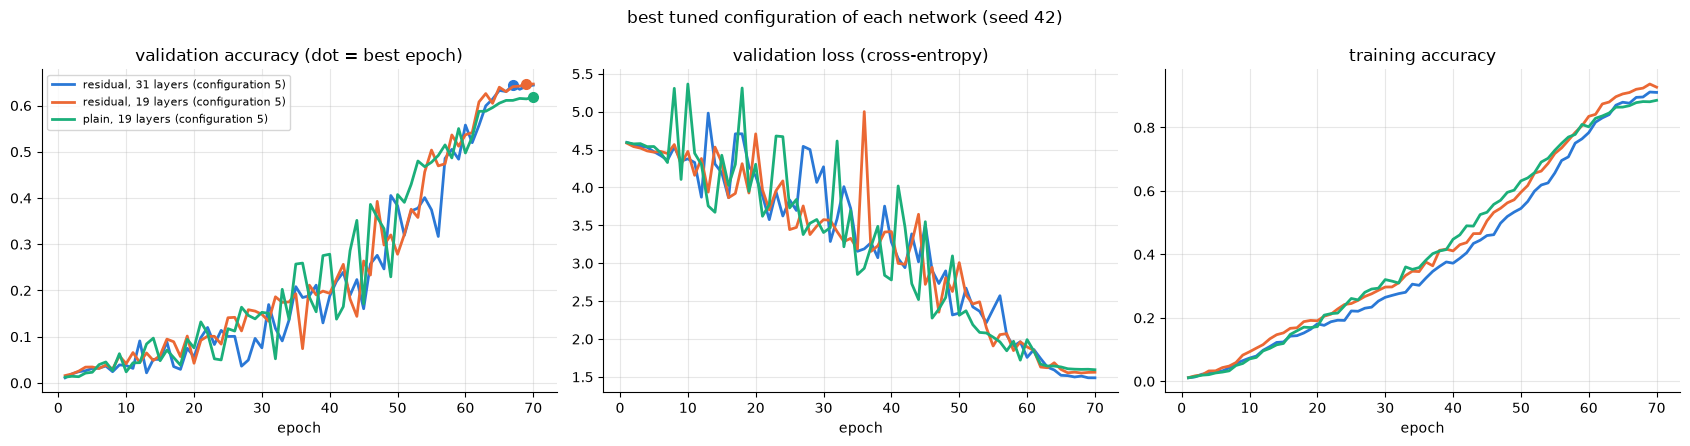

In [259]:
if names:
    groups, best_per_net = {}, {}
    for name in names:
        for variant, t in confirmed(name).items():
            if len(t) == len(SEEDS):
                groups[f"{label(name)} | {label(variant)}"] = t
        if best_tuned(name):
            best_per_net[name] = best_tuned(name)
    if groups:
        display(seed_summary(groups))
    if len(best_per_net) == len(names):
        ranked, selected = select({n: t for n, (_, t) in best_per_net.items()})
        print("configuration:", run_overrides(best_per_net[selected][1].run.iloc[0]))
        plot_curves({f"{label(n)} ({label(best_per_net[n][0])})": best_per_net[n][1].run.iloc[0]
                     for n in ranked}, "best tuned configuration of each network (seed 42)")

All three networks select that same configuration, which increases the validation accuracy compared to their
unregularized versions. Tuning confirms the hypothesis of the depth experiment: without regularization the 19-layer residual network was **worse** than the plain one, with the tuned recipe it is **better**. 

At 70 epochs the two residual networks perform very similar, so our rule would select the simpler one. However, all
three networks reach their best validation accuracy in the last epochs, with a training accuracy still around 90%:
they are still improving when training stops.

Selecting now would compare networks that have not finished training, so we first train them longer.

## 4. Longer training and the final model

We train the three tuned networks again for **150 epochs**, each with its best configuration and no other change,
with three seeds each. The one-cycle schedule is defined in fractions of the training, so it stretches with the number
of epochs: in the middle of a longer run the learning rate is still high, and validation accuracy only rises during
the final decay. Since the recipe was tuned for 70 epochs, a longer training also gives more time to overfit: if the gap between training and validation accuracy grew, the regularization tuned at 70 epochs would no longer be adequate and would have to be tuned again. We check that it does not grow.

In [260]:
# The longer trainings and the final model.

def long_runs(name):
    # The longer trainings of one network, over the seeds.
    return stored("long", name, f"ep{LONG_EPOCHS}")


def long_final():
    # {network: runs over the seeds} at LONG_EPOCHS, for the tuned networks; None until all are trained.
    names = finalists(TUNE_N) or []
    by_net = {n: long_runs(n) for n in names}
    return by_net if names and all(len(t) == len(SEEDS) for t in by_net.values()) else None


def final_network():
    # The final model: the selection rule applied after the longer training (None until it is trained).
    by_net = long_final()
    return select(by_net, verbose=False)[1] if by_net else None

In [261]:
# [run]
# The final model, stated explicitly: res_3461 with the best configuration of its recipe search (cfg05), trained
# for LONG_EPOCHS epochs. Its ablations each change exactly one component of this configuration.
FINAL_NET = "res_3461"
FINAL_CONFIG = {**dict(GRID)[FINAL_NET], "lr": 0.05, "weight_decay": 5e-3, "label_smoothing": 0.2,
                "dropout": 0.0, "random_erasing": 0.25, "crop_scale": (0.5, 1.0), "schedule": "onecycle",
                "epochs": LONG_EPOCHS}
if TRAIN:
    for seed in SEEDS:
        run_experiment(f"{FINAL_NET}_ep{LONG_EPOCHS}_s{seed}", "long", **{**FINAL_CONFIG, "seed": seed})

### Results

Each tuned network at 70 and at 150 epochs (mean ± standard deviation over three seeds) and the selection rule at 150
epochs; the curves compare the two budgets (seed 42).

,learning rate,seeds,parameters (M),validation (mean),validation (std),test (mean),test (std),final training (mean)
network,,,,,,,,
"plain, 19 layers | 70 epochs",0.05,3,11.07,0.630,0.011,0.631,0.008,0.892
"plain, 19 layers | 150 epochs",0.05,3,11.07,0.724,0.005,0.720,0.006,0.978
"residual, 31 layers | 70 epochs",0.05,3,11.91,0.642,0.003,0.647,0.005,0.905
"residual, 31 layers | 150 epochs",0.05,3,11.91,0.740,0.007,0.742,0.002,0.982
"residual, 19 layers | 70 epochs",0.05,3,11.25,0.641,0.007,0.640,0.003,0.931
"residual, 19 layers | 150 epochs",0.05,3,11.25,0.708,0.004,0.712,0.006,0.985


residual, 31 layers  150 epochs: validation 0.740 ± 0.007 | test 0.742 ± 0.002 | train 0.982
plain, 19 layers     150 epochs: validation 0.724 ± 0.005 | test 0.720 ± 0.006 | train 0.978
residual, 19 layers  150 epochs: validation 0.708 ± 0.004 | test 0.712 ± 0.006 | train 0.985
-> residual, 31 layers: better by 0.017, more than one standard deviation (0.007)
final configuration: {'img_size': 224, 'augment': True, 'crop_scale': [0.5, 1.0], 'stem': [32, 32, 64], 'channels': [64, 128, 256, 512], 'blocks': [3, 4, 6, 1], 'batchnorm': True, 'gap': True, 'residual': True, 'dropout': 0.0, 'epochs': 150, 'batch_size': 64, 'lr': 0.05, 'momentum': 0.9, 'weight_decay': 0.005, 'label_smoothing': 0.2, 'random_erasing': 0.25, 'warmup_epochs': 3, 'schedule': 'onecycle'}


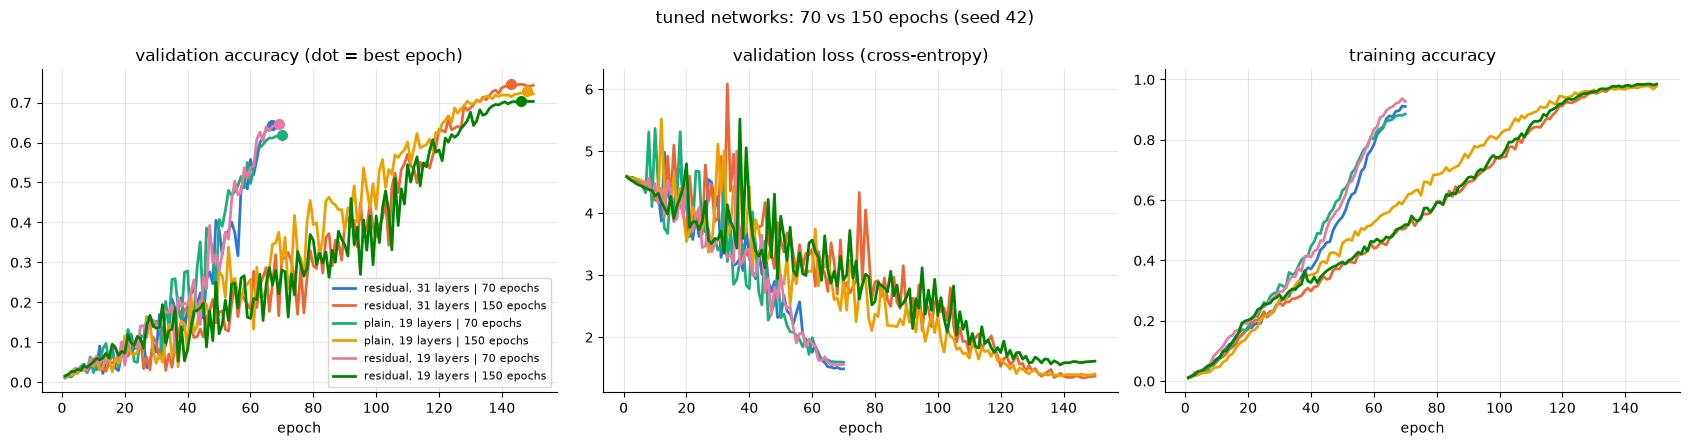

In [262]:
names = finalists(TUNE_N) or []
groups = {}
for name in names:
    if best_tuned(name):
        groups[f"{label(name)} | {BASE['epochs']} epochs"] = best_tuned(name)[1]
    if len(long_runs(name)):
        groups[f"{label(name)} | {LONG_EPOCHS} epochs"] = long_runs(name)
if groups:
    display(seed_summary(groups))

by_net = long_final()
if by_net:
    ranked, final = select(by_net, f"{LONG_EPOCHS} epochs: ")
    print("final configuration:", run_overrides(by_net[final].run.iloc[0]))
    curves = {}
    for n in ranked:
        curves[f"{label(n)} | {BASE['epochs']} epochs"] = best_tuned(n)[1].run.iloc[0]
        curves[f"{label(n)} | {LONG_EPOCHS} epochs"] = by_net[n].run.iloc[0]
    plot_curves(curves, f"tuned networks: {BASE['epochs']} vs {LONG_EPOCHS} epochs (seed 42)")

**Longer training improves validation accuracy** to every network, with no other change: at 70 epochs they were stopped too early.
**Overfitting does not increase**: the train–validation gap of the 31-layer residual network goes from 26 points at 70 epochs to 24 at
150, so the recipe tuned for 70 epochs still controls overfitting with a longer budget.

**The ranking changes.** At 150 epochs the 31-layer residual network is the best network, the deepest residual network benefits most from the additional training. Training only the winner at 70 epochs longer would have missed it.

**[Final model] The 31-layer residual network** combines every component justified by the previous experiments: BatchNorm, global average pooling, augmentation, a fourth stage, depth and residual
connections, with a tuned training recipe.

## 5. Ablation of the final model

The roadmap and the depth experiment added components one at a time to a plain network. To prove that every
design choice of the **final model** contributes to its accuracy, we now do the converse: starting from the final
network with its final configuration (150 epochs), we **remove one component at a time**, retrain, and compare with the
full model. Every ablation uses the same three seeds and changes exactly one thing.

| ablation | what changes | component tested |
|---|---|---|
| `no_batchnorm` | BatchNorm removed (convolutions get a bias back) | architecture |
| `no_gap` | flatten + linear head instead of global average pooling | architecture |
| `no_residual` | skip connections removed (plain network) | architecture |
| `no_stage4` | the 512-channel stage removed | architecture |
| `shallow` | one block per stage instead of the final layout | architecture |
| `no_augmentation` | no random resized crop and no horizontal flip | training recipe |
| `no_erasing` | no random erasing | training recipe |
| `no_label_smoothing` | plain cross-entropy | training recipe |
| `no_weight_decay` | weight decay 0 | training recipe |
| `cosine` | cosine schedule with warmup instead of one-cycle | training recipe |
| `no_batchnorm_lr0.01`, `no_gap_lr0.01` | the same removals at a learning rate of 0.01 | control |

**Control:** In the roadmap, networks without BatchNorm or with the flatten head were unstable at the high learning
rates that the final model uses. A removal could then look harmful only because the learning rate does not suit it, as
in the learning-rate sweep of the roadmap: for these two components we also train at a lower learning rate, and report
both.

**Reading the table:** `Δ val` is the validation accuracy of the ablated network minus that of the full model; a
component is useful if removing it lowers the accuracy by more than the seed noise (`beyond noise`: the drop exceeds
the larger standard deviation of the two). The train accuracy tells *how* a component helps: removing a regularizer
raises the train-validation gap, removing capacity or an optimization aid lowers the train accuracy itself.

In [263]:
# The ablations of the final model: each one changes exactly one component of its configuration
ABLATION_GROUP = "ablation"
ABLATION_LR_CONTROL = 0.01  # lr of the control runs for the components that make training unstable


def make_ablations(base):
    # {name: (kind, overrides)} on top of the configuration `base` of the final model; removals that would not
    # change `base` (e.g. no_residual on a plain network) are left out.
    channels, blocks = tuple(base["channels"]), tuple(base["blocks"])
    candidates = {
        "no_batchnorm": ("architecture", dict(batchnorm=False)),
        "no_gap": ("architecture", dict(gap=False)),
        "no_residual": ("architecture", dict(residual=False)),
        "no_stage4": ("architecture", dict(channels=channels[:3], blocks=blocks[:3])),
        "shallow": ("architecture", dict(blocks=(1,) * len(blocks))),
        "no_augmentation": ("recipe", dict(augment=False)),
        "no_erasing": ("recipe", dict(random_erasing=0.0)),
        "no_label_smoothing": ("recipe", dict(label_smoothing=0.0)),
        "no_weight_decay": ("recipe", dict(weight_decay=0.0)),
        "cosine": ("recipe", dict(schedule="cosine")),
        "no_batchnorm_lr0.01": ("control", dict(batchnorm=False, lr=ABLATION_LR_CONTROL)),
        "no_gap_lr0.01": ("control", dict(gap=False, lr=ABLATION_LR_CONTROL)),
    }
    same = lambda a, b: json.dumps(a) == json.dumps(b)  # tuples and lists compare equal
    return {n: (kind, over) for n, (kind, over) in candidates.items()
            if any(not same(base.get(k), v) for k, v in over.items())}


ABLATION_BASE = {**BASE, **FINAL_CONFIG}
ABLATIONS = make_ablations(ABLATION_BASE)

# check: the selection rule, applied to the stored longer runs, picks the same network and configuration
selected = final_network()
if selected is None:
    print("the longer runs are not stored: FINAL_CONFIG is not checked against the selection rule")
elif selected != FINAL_NET or run_overrides(long_runs(selected).run.iloc[0]) != json.loads(
        json.dumps({k: v for k, v in ABLATION_BASE.items() if k != "seed"})):
    print(f"WARNING: the selection rule picks {selected}, not FINAL_CONFIG")
print(f"final model: {FINAL_NET}, {ABLATION_BASE['epochs']} epochs, lr {ABLATION_BASE['lr']:g}")
for name, (kind, over) in ABLATIONS.items():
    print(f"{name:22s} {kind:13s} {over}")

final model: res_3461, 150 epochs, lr 0.05
no_batchnorm           architecture  {'batchnorm': False}
no_gap                 architecture  {'gap': False}
no_residual            architecture  {'residual': False}
no_stage4              architecture  {'channels': (64, 128, 256), 'blocks': (3, 4, 6)}
shallow                architecture  {'blocks': (1, 1, 1, 1)}
no_augmentation        recipe        {'augment': False}
no_erasing             recipe        {'random_erasing': 0.0}
no_label_smoothing     recipe        {'label_smoothing': 0.0}
no_weight_decay        recipe        {'weight_decay': 0.0}
cosine                 recipe        {'schedule': 'cosine'}
no_batchnorm_lr0.01    control       {'batchnorm': False, 'lr': 0.01}
no_gap_lr0.01          control       {'gap': False, 'lr': 0.01}


In [264]:
# [run]
if TRAIN:
    for name, (_, over) in ABLATIONS.items():
        for seed in SEEDS:
            run_experiment(f"{name}_s{seed}", ABLATION_GROUP, **{**ABLATION_BASE, **over, "seed": seed})

### Results of the ablation

Mean ± standard deviation over three seeds, each ablated network against the full model (the longer training of the
final network, same seeds).

In [265]:
def ablation_table():
    # One row per configuration, full model first: mean and standard deviation over the seeds and change against the
    # full model. Runs that diverged before the first validation are left out of the means.
    groups = {"full model": ("", {}, long_runs(FINAL_NET))}
    groups.update({name: (kind, over, stored(ABLATION_GROUP, name)) for name, (kind, over) in ABLATIONS.items()})
    groups = {name: g for name, g in groups.items() if len(g[2])}
    if len(groups) == 1:
        return None
    rows = []
    for name, (kind, over, t) in groups.items():
        ok = t[[r["best_epoch"] > 0 for r in t.run]]
        rows.append(dict(run=name, kind=kind, change=", ".join(f"{k}={v}" for k, v in over.items()),
                         val_mean=ok.val.mean(), val_std=ok.val.std(), test_mean=ok.test.mean(), test_std=ok.test.std(),
                         train=ok.train.mean(), gap=np.nanmean([r["final_train_acc"] - r["final_val_acc"] for r in t.run])))
    table = pd.DataFrame(rows).set_index("run")
    full = table.loc["full model"]
    table["d_val"], table["d_test"] = table.val_mean - full.val_mean, table.test_mean - full.test_mean
    noise = np.fmax(table.val_std, full.val_std)  # the larger standard deviation of the two
    table["beyond_noise"] = np.where(full.val_mean - table.val_mean > noise, "yes", "no")
    table.loc["full model", "beyond_noise"] = ""
    return table


# the columns shown in the table, and their names
ABLATION_COLUMNS = {"kind": "kind", "change": "change", "d_val": "Δ val", "d_test": "Δ test", "gap": "train-val gap",
                    "beyond_noise": "beyond noise"}


def style_ablation(table):
    return (table[list(ABLATION_COLUMNS)].rename(columns=ABLATION_COLUMNS)
            .style.format({"Δ val": "{:+.3f}", "Δ test": "{:+.3f}", "train-val gap": "{:+.3f}"}, na_rep="-")
            .background_gradient(subset=["Δ val", "Δ test"], cmap="RdYlGn", vmin=-0.4, vmax=0.4)
            .set_properties(subset=pd.IndexSlice["full model", :], **{"font-weight": "bold"}))


ablation = ablation_table() if len(long_runs(FINAL_NET)) else None
if ablation is None:
    print("no ablation run yet: run the cell above")
else:
    display(style_ablation(ablation))

,kind,change,Δ val,Δ test,train-val gap,beyond noise
run,,,,,,
full model,,,+0.000,+0.000,+0.244,
no_batchnorm,architecture,batchnorm=False,-0.730,-0.732,+0.000,yes
no_gap,architecture,gap=False,-0.227,-0.224,+0.481,yes
no_residual,architecture,residual=False,-0.174,-0.171,+0.126,yes
no_stage4,architecture,"channels=(64, 128, 256), blocks=(3, 4, 6)",-0.014,-0.016,+0.255,yes
shallow,architecture,"blocks=(1, 1, 1, 1)",-0.084,-0.087,+0.334,yes
no_augmentation,recipe,augment=False,-0.179,-0.172,+0.442,yes
no_erasing,recipe,random_erasing=0.0,+0.003,-0.004,+0.260,no
no_label_smoothing,recipe,label_smoothing=0.0,-0.018,-0.015,+0.259,yes


**Architecture.** Every component of the network is needed, but not equally.

- **BatchNorm is essential** (−73 points): without it the network does not train at all. The loss stays at ln(100) ≈ 4.6, the value of a random guess, and the network ends up predicting almost always the same class. The reason is the depth of our network: in a residual block the output is *added* to the input, so without BatchNorm the activations grow at every one of the 14 blocks. At the end they are very large, the gradients are very large too, and the first updates are huge steps that break the network. A 5× lower learning rate (0.01) shrinks the steps, since every update is learning rate × gradient, but it only reaches 8% validation accuracy: BatchNorm, which keeps the activations at the same scale in every block, is what makes this network trainable.
- **Global average pooling** (−23 points): with a flatten classifier the training–validation gap doubles (48 points instead of 24), so the network memorizes much more. A lower learning rate makes it even worse (−34), so the problem is overfitting, not optimization.
- **Residual connections** (−17 points): here the gap gets *smaller* (13 points), so the network without skip connections fits its training set worse. It is the degradation problem of section 2: the plain 31-layer network is hard to optimize.
- **Depth** (−8 points with one block per stage) matters much more than the **fourth stage** (−1.4 points), which has a single block.

Finally, **augmentation** (−18 points) and **weight decay** (−15 points) are the most important: without them the gap almost doubles (44 and 40 points), so the network overfits. **Label smoothing** gives a small but measurable gain (−1.8 points). **Random erasing** and the **one-cycle schedule** (instead of cosine) change the accuracy by less than the seed noise: at 150 epochs, with the other regularizers, they do not make a measurable difference, even though the random search had selected them at 70 epochs.


Training curves of every ablation (seed 42) against the full model: validation accuracy (solid) and training accuracy
(dashed).

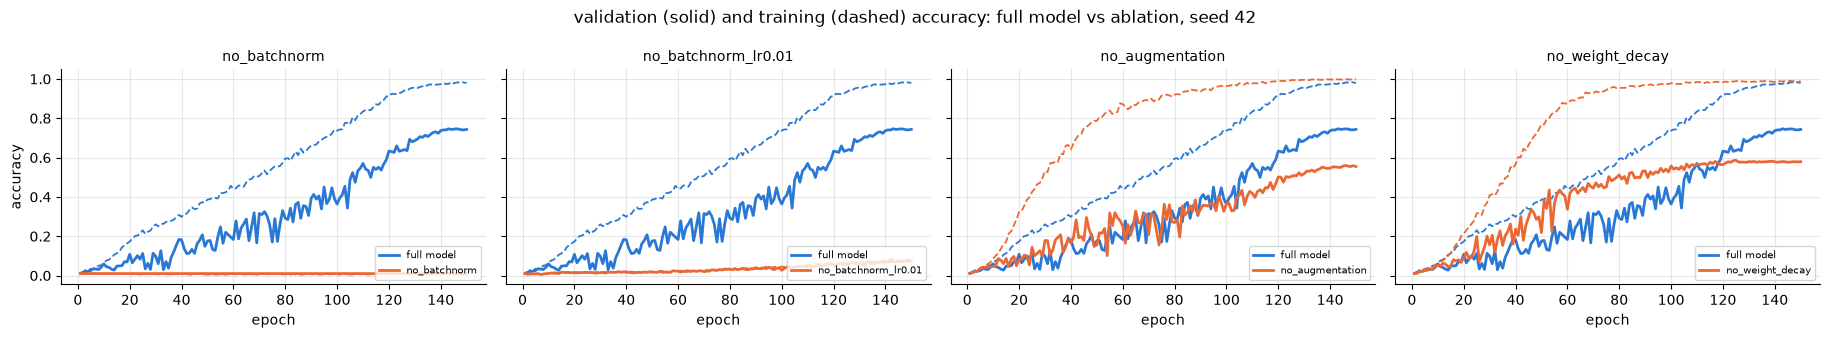

In [266]:
if ablation is not None:
    # the ablations discussed in the text: training collapse without BatchNorm, overfitting without the regularizers
    names = ["no_batchnorm", "no_batchnorm_lr0.01", "no_augmentation", "no_weight_decay"]
    reference = long_runs(FINAL_NET).run.iloc[0]
    fig, axes = plt.subplots(1, len(names), figsize=(4.6 * len(names), 3.4), sharey=True)
    for ax, name in zip(axes, names):
        ablated = stored(ABLATION_GROUP, name, seed=SEEDS[0]).run
        for curve_name, run, color in (("full model", reference, COLORS[0]),
                                       (name, ablated.iloc[0] if len(ablated) else None, COLORS[1])):
            if run is None or not run["history"]["val_acc"]:
                continue
            h = run["history"]
            ep = range(1, len(h["val_acc"]) + 1)
            ax.plot(ep, h["val_acc"], color=color, label=curve_name)
            ax.plot(ep, h["train_acc"], color=color, ls="--", lw=1.3)
        ax.set_title(name, fontsize=10); ax.set_xlabel("epoch"); ax.legend(fontsize=7, loc="lower right")
    axes[0].set_ylabel("accuracy")
    fig.suptitle("validation (solid) and training (dashed) accuracy: full model vs ablation, seed 42")
    plt.tight_layout(); plt.show()

## Conclusions

On a dataset this small, the main obstacle is not designing a powerful network but stopping it from memorizing
33 images per class. Most of our gains came from controlling that: global average pooling, augmentation and weight
decay matter as much as the architecture itself.

Depth helps only with residual connections and only once overfitting is controlled: the same skip connections
that hurt the shallow networks without regularization made the 31-layer network the best one after tuning and
longer training. Decisions taken too early would have missed this: the best network was a plain one without regularization, a 19-layer residual one after tuning, and the 31-layer residual one only after longer training.

Finally, not every choice of the search turned out to matter: the ablation shows that some components selected
at 70 epochs bring no measurable benefit in the final model, while BatchNorm, which we added first, is the one the
network cannot do without.

# Part 2: fine-tune a pretrained ResNet-18

We now fine-tune the ResNet-18 of PyTorch, pretrained on ImageNet-1K (V1 weights), with the same data, splits,
training loop and evaluation as Part 1. Only two things change:

1. **the network**: the pretrained ResNet-18, whose 1000-way ImageNet classifier is replaced by a new, randomly
   initialized 100-way linear layer;
2. **the input normalization**: the pretrained filters expect images normalized with the ImageNet mean and standard
   deviation, not with those of our training split.

## 2A: the hyperparameters of Part 1

As the assignment requires, we first fine-tune the whole network with exactly the training recipe of our final
model of Part 1, without tuning anything:

| hyperparameter | value |
|---|---|
| epochs | 150 |
| optimizer | SGD, momentum 0.9, batch size 64 |
| learning rate | 0.05, one-cycle schedule |
| weight decay | 5e-3 |
| label smoothing | 0.2 |
| dropout | 0 |
| augmentation | random resized crop (at least 50% of the image), horizontal flip, random erasing (p = 0.25) |

This recipe, and in particular its learning rate, was tuned for a network trained from scratch. 2A shows how it
behaves on pretrained weights, and is the starting point of 2B. As in Part 1, we train three seeds (42, 43, 44).


In [267]:
# the training hyperparameters of the best model of Part 1 (res_3461, configuration cfg05), applied to the pretrained net
FINETUNE = dict(pretrained=True, augment=True, crop_scale=(0.5, 1.0), dropout=0.0, epochs=LONG_EPOCHS, lr=0.05,
                weight_decay=5e-3, label_smoothing=0.2, random_erasing=0.25, schedule="onecycle")

# check: the same recipe as the stored best configuration of res_3461 in Part 1
best = best_tuned(FINAL_NET)
if best is not None:
    reference = run_overrides(best[1].run.iloc[0])
    differences = {k: (reference.get(k), v) for k, v in FINETUNE.items() if k not in ("pretrained", "epochs")
                   and json.loads(json.dumps(reference.get(k))) != json.loads(json.dumps(v))}
    print("same recipe as Part 1" if not differences else f"WARNING: differs from Part 1 (part 1, here): {differences}")

same recipe as Part 1


### Fine-tuning

Three seeds, same configuration: there is no learning-rate sweep, so the mean over the seeds is not biased by a
selection (in Part 1 the seed-42 run of a configuration is the best of three learning rates).

In [268]:
# [run]
if TRAIN:
    for seed in SEEDS:
        run_experiment(f"resnet18_ft_s{seed}", "finetune", results_dir=RESULTS_DIR_2A, seed=seed, **FINETUNE)

### Results of 2A

Mean ± standard deviation over three seeds, compared with the best model of Part 1 trained from scratch with the same
hyperparameters (`res_3461`, 150 epochs). The curves are the seed-42 runs.

,learning rate,seeds,parameters (M),validation (mean),validation (std),test (mean),test (std),final training (mean)
network,,,,,,,,
"resnet18_ft (pretrained, 2A)",0.05,3,11.23,0.719,0.007,0.724,0.007,0.993
"res_3461 (from scratch, part 1)",0.05,3,11.91,0.740,0.007,0.742,0.002,0.982


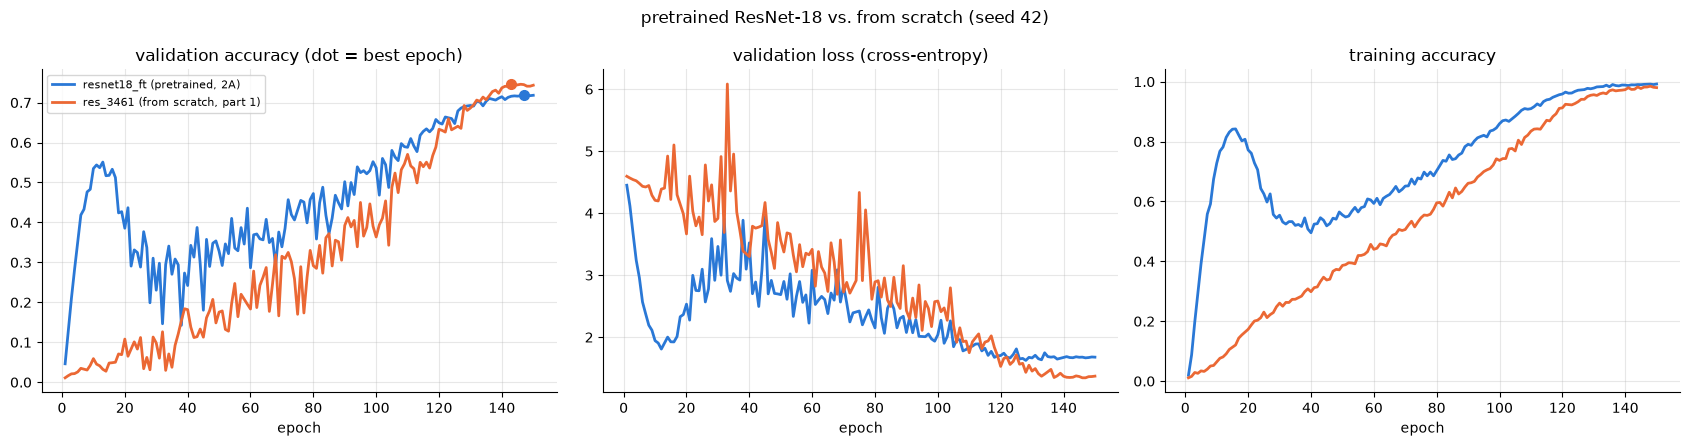

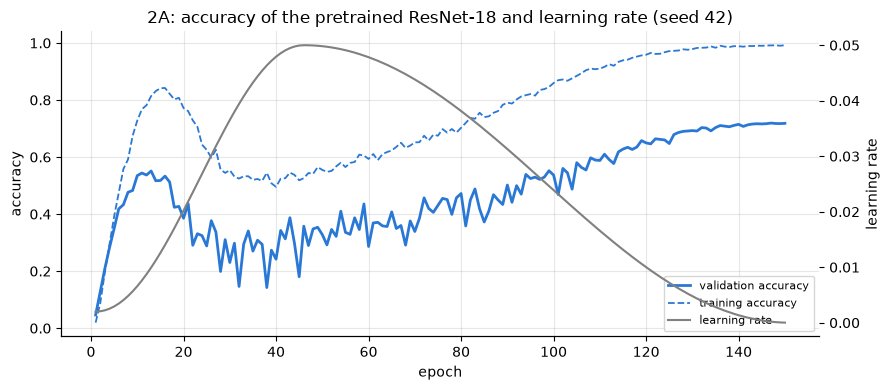

In [269]:
finetune = stored("finetune")
groups = {"resnet18_ft (pretrained, 2A)": finetune, f"{FINAL_NET} (from scratch, part 1)": long_runs(FINAL_NET)}
groups = {k: t for k, t in groups.items() if len(t)}
if len(finetune):
    display(seed_summary(groups))
    plot_curves({k: t.run.iloc[0] for k, t in groups.items()}, "pretrained ResNet-18 vs. from scratch (seed 42)")

    # the accuracy of the pretrained network against its learning rate (seed 42)
    h = finetune.run.iloc[0]["history"]
    ep = range(1, len(h["lr"]) + 1)
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(ep, h["val_acc"], color=COLORS[0], label="validation accuracy")
    ax.plot(ep, h["train_acc"], color=COLORS[0], ls="--", lw=1.3, label="training accuracy")
    ax.set_xlabel("epoch"); ax.set_ylabel("accuracy")
    ax_lr = ax.twinx()
    ax_lr.plot(ep, h["lr"], color="gray", lw=1.5, label="learning rate")
    ax_lr.set_ylabel("learning rate"); ax_lr.grid(False)
    ax.legend(*[a + b for a, b in zip(ax.get_legend_handles_labels(), ax_lr.get_legend_handles_labels())],
              loc="lower right", fontsize=8)
    ax.set_title("2A: accuracy of the pretrained ResNet-18 and learning rate (seed 42)")
    plt.tight_layout(); plt.show()
else:
    print("no stored run yet")

**Part 1's recipe does not suit a pretrained network.** The pretrained ResNet-18 starts much faster than the network trained from scratch, but its accuracy collapses as the one-cycle schedule raises the learning rate towards 0.05, long before the peak. Even its *training* accuracy falls: the large updates overwrite the ImageNet features that made the start fast. The network recovers only once the learning rate decays, and ends below the network trained from scratch, so with these hyperparameters the pretraining is largely wasted. 2B adapts the recipe to fine-tuning, starting from a much lower learning rate.


## 2B: adapting the recipe to fine-tuning

2A shows that the recipe of Part 1 is not suited to a pretrained network: its learning rate overwrites the ImageNet
features. In 2B we adapt the recipe **one aspect at a time**, each step starting from the best configuration of the
previous one, so that every change in accuracy has a single cause:

1. **Learning rate and weight decay.** Smaller updates, so that the pretrained features are refined instead of erased.
2. **Frozen warmup and schedule.** The new classifier is trained first, with the backbone frozen, before fine-tuning
   everything.
3. **Progressive learning rates.** The early, generic layers learn more slowly than the late ones, or stay frozen.
4. **Data augmentation.** Stronger augmentation, now that the network fits the training set quickly.
5. **Classifier regularization.** Label smoothing and dropout, re-tuned for the new recipe; the two best recipes are
   confirmed with three seeds.
6. **Longer training and resolution.** The winner is trained for 150 epochs, with random erasing and with larger
   images, and the best configuration is confirmed with three seeds.

Steps 1–5 use one seed and 70 epochs, as the exploration of Part 1. Step 6 uses 150 epochs. All the choices are made on the validation split. 

**Result.** The final recipe fine-tunes the pretrained ResNet-18 at 320x320 for 150 epochs and reaches **81.5% test accuracy**, well above our network trained from scratch and the recipe of 2A.

In [270]:
def grid(t, rows, cols):
    # Best validation accuracy of a grid of runs, one hyperparameter on the rows and one on the columns (the values of
    # each run's own configuration: in the table of all the runs, a key missing from some runs becomes a float).
    keys = pd.DataFrame({k: [r["config"][k] for r in t.run] for k in (rows, cols)}).assign(val=t.val.to_numpy())
    return keys.pivot(index=rows, columns=cols, values="val").style.background_gradient(cmap="Blues", axis=None).format("{:.3f}")


def config_table(runs, keys):
    # One row per run ({label: run}): the hyperparameters that differ between the runs, and its accuracy.
    rows = [{**{k: r["config"].get(k) for k in keys}, "best validation": r["best_val_acc"], "test": r["test_acc"],
             "final training": r["final_train_acc"], "best epoch": r["best_epoch"]} for r in runs.values()]
    return pd.DataFrame(rows, index=list(runs)).style.format(
        {"best validation": "{:.3f}", "test": "{:.3f}", "final training": "{:.3f}"}, na_rep="-")


def best_per(t, key):
    # For each value of one hyperparameter (increasing), the run with the best validation accuracy.
    return [best_run(g).run for _, g in t.groupby(key)]


def confirmed_s5():
    # {recipe: runs over the seeds} for the TOP_K best recipes of step 5.
    top = stored("s5_reg", seed=SEEDS[0]).sort_values("val", ascending=False, kind="stable").network[:TOP_K]
    return {n: stored("s5_reg", n) for n in top}

### Step 1: learning rate and weight decay

Pretrained weights already lie in a good region of the loss surface: updates that are too large leave it, and the first
epochs of 2A show it (Yosinski et al., NeurIPS 2014). Weight decay is a second suspect: $L_2$ decay pulls the weights
towards zero, not towards the pretrained values (Li et al., ICML 2018), so the large value of Part 1 (5e-3) could erase
the ImageNet features. We search a 4 x 4 log-spaced grid of smaller learning rates and weight decays, with all the
other hyperparameters as in 2A, for 70 epochs. The plot shows, for each learning rate, its best weight decay.

weight_decay,0.000100,0.000500,0.001000,0.005000
lr,,,,
0.001000,0.599,0.605,0.604,0.610
0.002000,0.645,0.648,0.649,0.661
0.005000,0.677,0.676,0.673,0.696
0.010000,0.692,0.696,0.696,0.717


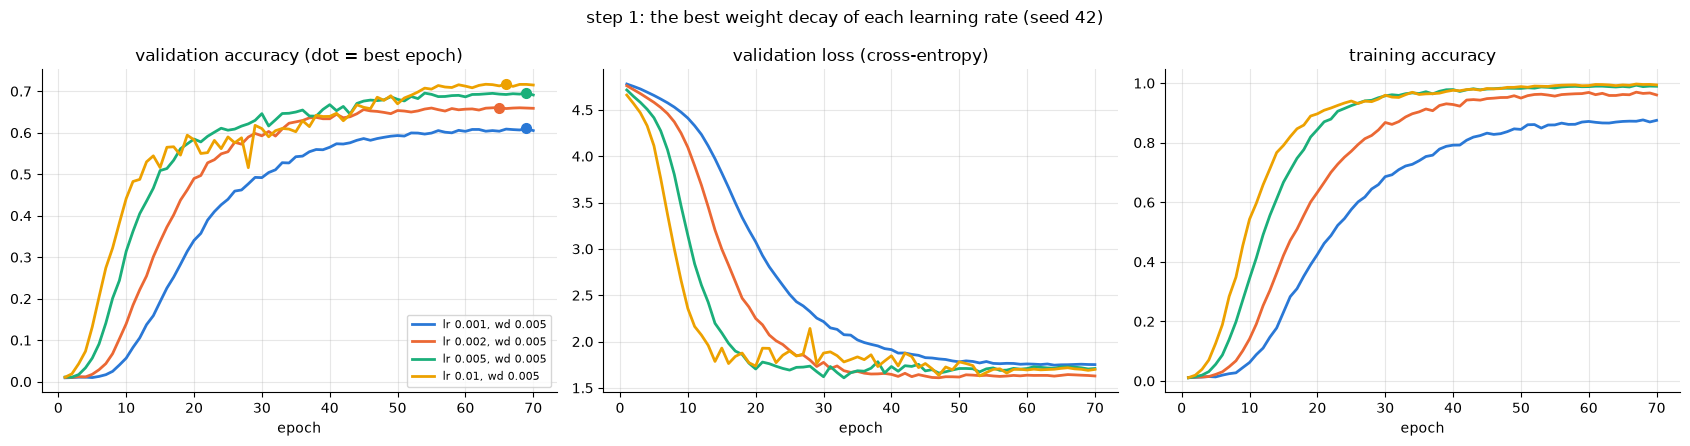

In [271]:
s1 = stored("s1_lr_wd")
if len(s1):
    display(grid(s1, "lr", "weight_decay"))
    plot_curves({f"lr {r['config']['lr']:g}, wd {r['config']['weight_decay']:g}": r for r in best_per(s1, "lr")},
                "step 1: the best weight decay of each learning rate (seed 42)")

**The learning rate is what matters, and 2A's was too large.** 

Accuracy grows with the learning rate over the whole range. At the smallest values the network does not even fit its training set. Weight decay has a smaller effect, and
not the expected one: the *largest* value, 5e-3, is the best at every learning rate, so the pretrained features are not erased by the decay. What erased them in 2A was the higher learning rate. 

With 70 epochs the best run (**71.7%**) already matches 2A trained for 150. The best learning rate is the largest of the grid: the optimum may lie between 0.01 and 0.05, which we do not explore. We keep **learning rate 0.01 and weight decay 5e-3**.


### Step 2: frozen warmup of the classifier and schedule

At the first epoch the 100-way classifier is random, while the backbone holds good features: updating everything at
once sends large random gradients into the backbone and distorts its features (Kumar et al., *Fine-Tuning can Distort
Pretrained Features*, ICLR 2022). Their remedy, **linear probing then fine-tuning**, first trains the classifier with the
backbone frozen, then unfreezes everything. We freeze the backbone for the first 0, 3, 5 or 10 epochs (its BatchNorm
layers stay in evaluation mode, so that their ImageNet statistics are not altered), and compare the one-cycle schedule
with a cosine schedule with 3 warmup epochs.

In [272]:
s2 = stored("s2_warmup")
if len(s2):
    display(grid(s2, "schedule", "freeze_epochs"))

freeze_epochs,0,3,5,10
schedule,,,,
cosine,0.719,0.722,0.716,0.702
onecycle,0.717,0.718,0.720,0.723


**Freezing the backbone and the schedule change little.** Apart from the worst combination (cosine schedule with 10
frozen epochs), all the runs are within about one point, a difference comparable to the run-to-run noise of 2A. The
best run freezes the backbone for 10 epochs with the one-cycle schedule (**72.3%**), slightly above no freezing: we
keep it, but the evidence for a warmup of the classifier is weak.

### Step 3: progressive learning rates and frozen stages

The first layers of a convolutional network detect edges and textures that transfer across domains, the last ones
detect parts of the object (Yosinski et al., NeurIPS 2014). **Discriminative fine-tuning** gives smaller learning rates
to the earlier stages (Howard & Ruder, ACL 2018): the stage $s$ of the six of the network (stem, the four residual
stages, classifier) learns at $\text{lr} \cdot \gamma^{5-s}$. We cross $\gamma \in \{1, 0.7, 0.5, 0.3\}$ with the number
of lowest stages kept frozen during the whole training (0 = none, 1 = the stem, 2 = the stem and the first stage).

freeze_stages,0,1,2
layer_decay,,,
0.300000,0.622,0.626,0.626
0.500000,0.661,0.663,0.661
0.700000,0.688,0.689,0.681
1.000000,0.723,0.719,0.714


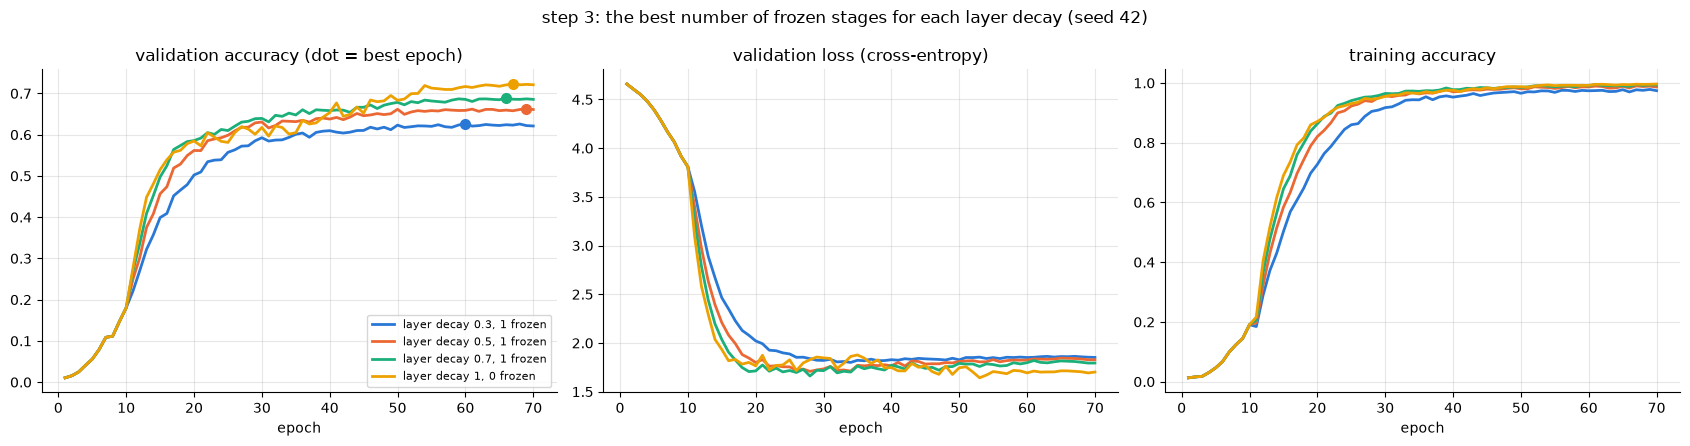

In [273]:
s3 = stored("s3_proglr")
if len(s3):
    display(grid(s3, "layer_decay", "freeze_stages"))
    plot_curves({f"layer decay {r['config']['layer_decay']:g}, {r['config']['freeze_stages']} frozen": r
                 for r in best_per(s3, "layer_decay")},
                "step 3: the best number of frozen stages for each layer decay (seed 42)")

**All the layers should learn at the same rate.** Validation accuracy falls steadily as the decay grows, and so does
the training accuracy; freezing the lowest stages does not help either. Lowering the learning rate of the early layers
has the same effect as lowering the learning rate of the whole network in step 1: the network underfits. **Aircraft
photographs are different enough from ImageNet that the early filters need to adapt as well**. The best run is the one
without decay or frozen stages (**72.3%** validation accuracy, the result of step 2): we keep a single learning rate
and no frozen stage, so this step does not change the recipe.


### Step 4: data augmentation

With about 33 images per class, a network that keeps its pretrained features fits the training set quickly. In Part 1,
stronger augmentation was left out because it makes optimization harder from random weights. 

**4A** crosses the minimum area of the random crop (50%, 35%, 25% of the image, forcing the network to recognize parts at several scales) with the probability of random erasing (0, 0.25, 0.5; Zhong et al., AAAI 2020). 

**4B**, on top of the best 4A, tests brightness and contrast jitter (0.2), **Mixup** ($\alpha$ = 0.2; Zhang et al.,
ICLR 2018) and **CutMix** ($\alpha$ = 0.5 and 1; Yun et al., ICCV 2019).

In [274]:
s4a, s4b = stored("s4_aug_spatial"), stored("s4_aug_mix")
if len(s4a):
    crops = pd.DataFrame({"minimum crop area": [c[0] for c in s4a.crop_scale],
                          "random erasing": s4a.random_erasing.to_numpy(), "val": s4a.val.to_numpy()})
    display(crops.pivot(index="minimum crop area", columns="random erasing", values="val")
            .style.background_gradient(cmap="Blues", axis=None).format("{:.3f}"))
if len(s4b):
    display(config_table({r["name"]: r for r in s4b.run}, ["color_jitter", "mixup_alpha", "cutmix_alpha"]))

random erasing,0.000000,0.250000,0.500000
minimum crop area,,,
0.250000,0.707,0.701,0.698
0.350000,0.712,0.712,0.700
0.500000,0.727,0.723,0.714


,color_jitter,mixup_alpha,cutmix_alpha,best validation,test,final training,best epoch
s4b_mix_cutmix05,0.000000,0.000000,0.500000,0.719,0.711,0.822,68
s4b_mix_cutmix10,0.000000,0.000000,1.000000,0.711,0.707,0.861,62
s4b_mix_jitter02,0.200000,0.000000,0.000000,0.740,0.729,1.000,69
s4b_mix_mixup02,0.000000,0.200000,0.000000,0.733,0.723,0.981,64
s4b_mix_none,0.000000,0.000000,0.000000,0.727,0.731,1.000,70


**Stronger augmentation does not help, except for colour jitter.** In 4A the mildest setting is the best: crops of at
least 50% of the image and no random erasing; smaller crops and more erasing lower the accuracy. In 4B, CutMix makes
the training task too hard for 70 epochs (the training accuracy stays well below 100%) and lowers the accuracy, Mixup
is neutral, and **colour jitter gives the best validation accuracy, 74.0%**. Its test accuracy, however, is not
higher than without it, and this is a single run with a small gain: it is the weakest decision of 2B. We keep the
jitter, and a crop of at least 50% without random erasing.


### Step 5: regularization of the classifier, confirmation with seeds

Finally we tune the two regularizers of the classifier, **label smoothing** (0, 0.05, 0.1, 0.2; Szegedy et al., CVPR
2016) and **dropout** before the linear layer (0, 0.2, 0.4; Srivastava et al., JMLR 2014), whose best values may differ
now that the backbone and the augmentation have changed. To avoid selecting the luckiest single run, the **two best
recipes are retrained with two more seeds**, and the one with the best mean validation accuracy is the result of 2B.

In [275]:
s5 = stored("s5_reg", seed=SEEDS[0])
if len(s5):
    display(grid(s5, "label_smoothing", "dropout"))
confirmed_2b = confirmed_s5()
if confirmed_2b:
    display(seed_summary(confirmed_2b))

dropout,0.000000,0.200000,0.400000
label_smoothing,,,
0.000000,0.731,0.739,0.740
0.050000,0.735,0.728,0.737
0.100000,0.743,0.736,0.742
0.200000,0.740,0.740,0.746


,learning rate,seeds,parameters (M),validation (mean),validation (std),test (mean),test (std),final training (mean)
network,,,,,,,,
s5_ls0.2_dp0.4,0.01,3,11.23,0.748,0.001,0.741,0.003,1.000
s5_ls0.1_dp0,0.01,3,11.23,0.736,0.005,0.733,0.003,1.000


**Classifier regularization matters little, and closes the exploration at 74.8%.** The twelve combinations are within
about two points and no regularizer dominates: the two best ones make opposite choices (label smoothing 0.2 with
dropout 0.4, label smoothing 0.1 without dropout). With three seeds, label smoothing 0.2 with dropout 0.4 is better,
and it also varies less between seeds: **74.8% ± 0.1 validation accuracy** at 70 epochs. This recipe is the starting
point of step 6.


### Summary of the steps

The best run (seed 42) of every step, against the baseline of 2A (150 epochs).

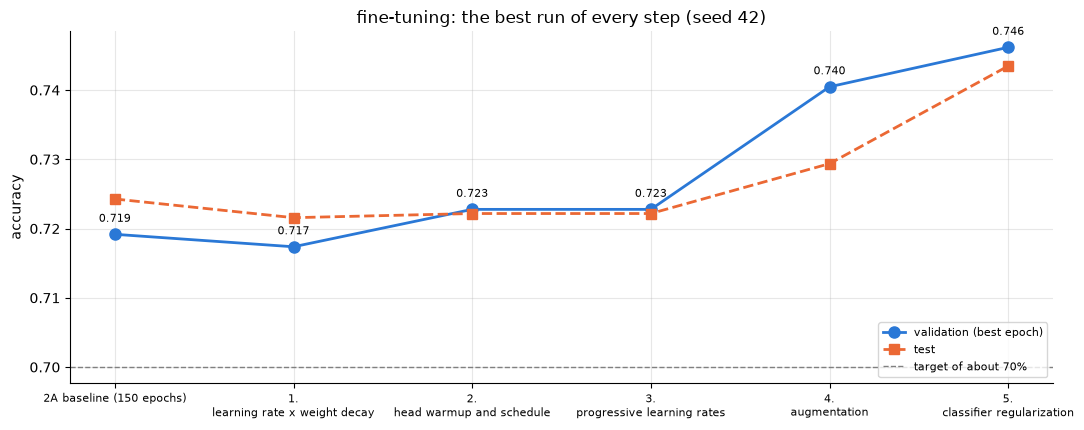

In [276]:
steps_2b = {}
baseline = stored("finetune")
if len(baseline):
    steps_2b["2A baseline (150 epochs)"] = baseline.run.iloc[0]
for name, experiment in [("1. learning rate x weight decay", "s1_lr_wd"), ("2. head warmup and schedule", "s2_warmup"),
                         ("3. progressive learning rates", "s3_proglr"), ("4. augmentation", "s4_aug_mix"),
                         ("5. classifier regularization", "s5_reg")]:
    t = stored(experiment, seed=SEEDS[0])
    if len(t):
        steps_2b[name] = best_run(t).run

if steps_2b:
    names = list(steps_2b)
    xs = np.arange(len(names))
    fig, ax = plt.subplots(figsize=(11, 4.4))
    ax.plot(xs, [steps_2b[n]["best_val_acc"] for n in names], "o-", color=COLORS[0], markersize=8, label="validation (best epoch)")
    ax.plot(xs, [steps_2b[n]["test_acc"] for n in names], "s--", color=COLORS[1], markersize=7, label="test")
    for x_, n in zip(xs, names):
        ax.annotate(f"{steps_2b[n]['best_val_acc']:.3f}", (x_, steps_2b[n]["best_val_acc"]), textcoords="offset points",
                    xytext=(0, 9), ha="center", fontsize=8)
    ax.set_xticks(xs, [n.replace(". ", ".\n", 1) for n in names], fontsize=8)
    ax.axhline(0.70, ls="--", c="gray", lw=1, label="target of about 70%")
    ax.set_ylabel("accuracy"); ax.legend(loc="lower right", fontsize=8)
    ax.set_title("fine-tuning: the best run of every step (seed 42)")
    plt.tight_layout(); plt.show()

Steps 1, 4 and 5 are the ones that raise the accuracy: the smaller learning rate lifts the network to the level of 2A
in less than half of the epochs, and the following steps add about 3 points in total, mostly from step 4 (colour jitter).
Steps 2 and 3 do not change the result (the winner of step 3 is the one of step 2). Note that the baseline of 2A is
trained for 150 epochs and the other runs for 70, and that there is no run of 2A with 70 epochs.

### Step 6: longer training and higher resolution

We train the recipe of step 5 for 150 epochs, the budget of the final models of Part 1 and 2A, and test two changes
on top of it:

- **Random erasing** (p = 0.25): without it the training accuracy reaches 100% well before the end of the longer
  training; erasing could delay this memorization.
- **Higher resolution** (320x320 instead of 224x224): the network ends with global average pooling, so the same
  pretrained weights accept larger images, and the last feature map grows from 7x7 to 10x10, with more detail for the
  small parts that separate the variants (Lin et al., ICCV 2015; Touvron et al., NeurIPS 2019).

The four combinations (with and without each change) are trained with seed 42; the best one on validation is
confirmed with three seeds and is the final model of 2B.


,resolution,random erasing,validation,test
"224 px, no erasing (baseline)",224,0,0.766,0.767
"224 px, erasing 0.25",224,0.25,0.755,0.760
"320 px, no erasing",320,0,0.805,0.826
"320 px, erasing 0.25",320,0.25,0.808,0.814


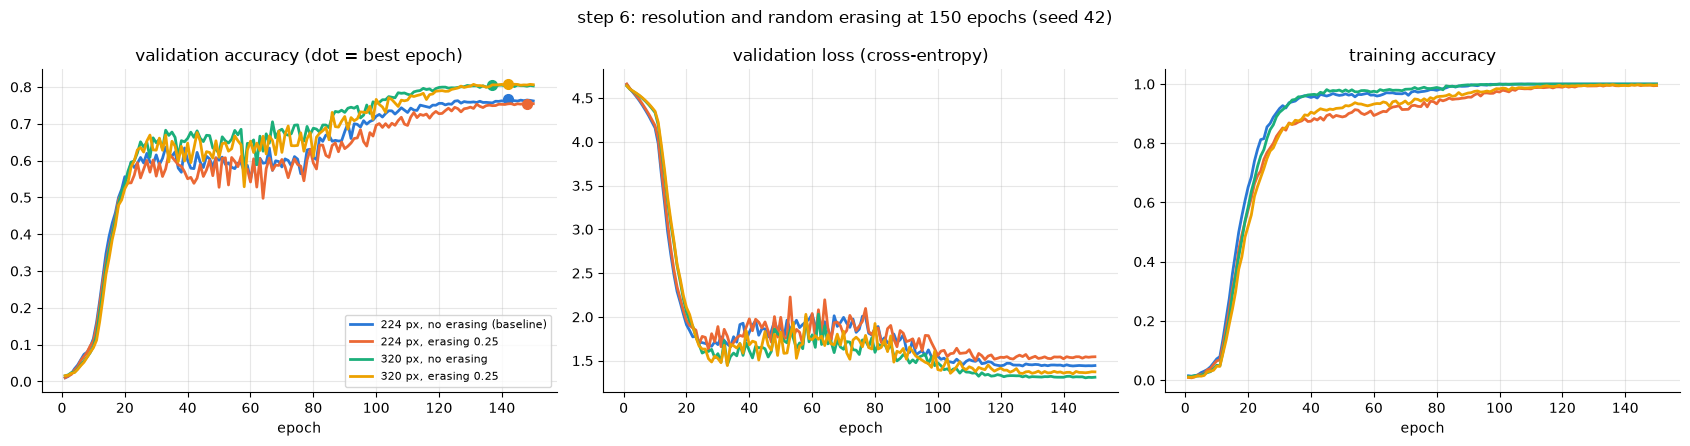

In [277]:
s6_runs = {r["name"]: r for r in stored("s6_highres").run}
base_150 = stored("final_long", seed=SEEDS[0])
if not len(base_150) or len(s6_runs) < 3:
    print("the runs of step 6 are not stored yet (groups final_long and s6_highres of results/part2B)")
else:
    s6_compare = {
        "224 px, no erasing (baseline)": base_150.run.iloc[0],
        "224 px, erasing 0.25": s6_runs["s6a_224px_re0.25_ep150"],
        "320 px, no erasing": s6_runs["s6b_320px_re0_ep150"],
        "320 px, erasing 0.25": s6_runs["s6c_320px_re0.25_ep150"],
    }
    display(pd.DataFrame([{"resolution": r["config"]["img_size"], "random erasing": r["config"]["random_erasing"],
                           "validation": r["best_val_acc"], "test": r["test_acc"]} for r in s6_compare.values()],
                         index=list(s6_compare)).style.format({"random erasing": "{:g}", "validation": "{:.3f}",
                                                               "test": "{:.3f}"}))
    plot_curves(s6_compare, "step 6: resolution and random erasing at 150 epochs (seed 42)")

**Resolution is what matters.** At 224x224, random erasing does not help: the training accuracy still reaches almost
100%, and the validation accuracy is slightly lower than without it. At 320x320 the validation accuracy increases with or without erasing.


### Comparison with Part 1 and 2A

Mean ± standard deviation over the three seeds: our final network of Part 1 trained from scratch (150 epochs), the
pretrained network with the recipe of Part 1 (2A, 150 epochs), and the tuned recipe of 2B at 70 epochs, at 150 epochs,
and with the resolution and random erasing selected in step 6 (150 epochs).

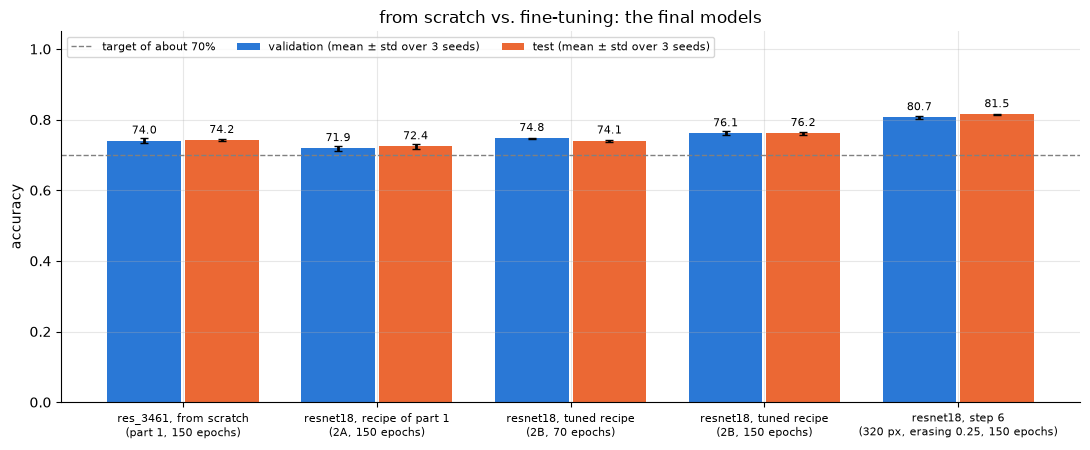

In [278]:
best_2b = best_confirmed(confirmed_s5())
s6_final = stored("s6_final_seeds")
final_groups = {
    f"{FINAL_NET}, from scratch (part 1, 150 epochs)": long_runs(FINAL_NET),
    "resnet18, recipe of part 1 (2A, 150 epochs)": stored("finetune"),
    "resnet18, tuned recipe (2B, 70 epochs)": best_2b[1] if best_2b else pd.DataFrame(),
    f"resnet18, tuned recipe (2B, {LONG_EPOCHS} epochs)": stored("final_long"),
}
if len(s6_final):
    cfg = s6_final.run.iloc[0]["config"]
    final_groups[f"resnet18, step 6 ({cfg['img_size']} px, erasing {cfg['random_erasing']:g}, {LONG_EPOCHS} epochs)"] = s6_final
final_groups = {k: t for k, t in final_groups.items() if len(t)}

if final_groups:
    names = list(final_groups)
    xs = np.arange(len(names))
    fig, ax = plt.subplots(figsize=(11, 4.6))
    for offset, key, name, color in ((-0.2, "val", "validation", COLORS[0]), (0.2, "test", "test", COLORS[1])):
        means = [final_groups[n][key].mean() for n in names]
        ax.bar(xs + offset, means, 0.38, yerr=[final_groups[n][key].std() for n in names], capsize=3, color=color,
               label=f"{name} (mean ± std over 3 seeds)")
        for x_, m in zip(xs + offset, means):
            ax.text(x_, m + 0.02, f"{100 * m:.1f}", ha="center", fontsize=8)
    ax.axhline(0.70, ls="--", c="gray", lw=1, label="target of about 70%")
    ax.set_xticks(xs, [n.replace(" (", "\n(", 1) for n in names], fontsize=8)
    ax.set_ylim(0, 1.05); ax.set_ylabel("accuracy"); ax.legend(loc="upper left", ncol=3, fontsize=8)
    ax.set_title("from scratch vs. fine-tuning: the final models")
    plt.tight_layout(); plt.show()

## Conclusions

The hyperparameters of a network trained from scratch do not transfer to fine-tuning. With the recipe of Part 1 the
pretrained ResNet-18 ends below our own network: its learning rate, tuned for random weights, overwrites the ImageNet
features in the first epochs. A ten times smaller learning rate is the single change that recovers them.

Most of the techniques designed for fine-tuning brought little: freezing the backbone at the start, smaller learning
rates for the early layers and stronger augmentation such as Mixup and CutMix all stayed within the noise or made
things worse. Aircraft photographs are different enough from ImageNet that every layer needs to adapt, at the same
rate. What mattered instead were the learning rate, a longer training and the input resolution: since the network
ends with global average pooling, 320x320 images cost no change to the architecture and gave the largest gain of all,
bringing the final model to **81.5% test accuracy**.

Pretraining pays off most when training is short: in 70 epochs the tuned recipe already matches what our network
trained from scratch reaches in 150. With the same budget and resolution the advantage shrinks to a few points, and
the gap between the two parts comes as much from how the pretrained network is trained as from the pretraining
itself.